# Proyecto MA4703 Control Óptimo — Avance 3: objetivos 3 a 8
## Control estocástico del modelo de Black-Scholes (problema de Merton)

* Profesor: Héctor Ramírez.
* Auxiliares: Hernán Torres, Diego Morales.
* Ayudante: Fraick Reyes.
* Integrantes: Bonnie Lagos, Javier Cruz.

**Objetivo de este avance.** Completar los objetivos del enunciado que el reporte de avances dejó pendientes. Los avances 1 y 2 cubrieron la controlabilidad (objetivo 1) y la simulación con Monte-Carlo (objetivo 2); este notebook cubre el resto:

| Objetivo del enunciado | Sección |
| --- | --- |
| 3. Utilizar filtros de Kalman para estimar los parámetros de la dinámica | 1 |
| 4. Estudiar la existencia de controles óptimos | 2.4 |
| 5. Caracterizar los controles óptimos mediante programación dinámica y resolución numérica de la HJB | 2.1 a 2.3 |
| 6. Estudiar qué ocurre cuando se acota el espacio de controles admisibles | 2.5 |
| 7. Acotar el tiempo del sistema a un tiempo $T$ finito o a un tiempo de parada $\tau$ | 3 |
| 8. Extensiones | 4 |

Cada sección termina con sus conclusiones y pendientes. Los gráficos se guardan también, uno por uno, en `figuras_poster/` (PNG de 300 dpi), y las figuras del reporte en `figuras_final/`.

**Referencias.** [KS] Karatzas–Shreve, *Brownian Motion and Stochastic Calculus*; [R] Ross, *Stochastic Control in Continuous Time*; [KD] Kushner–Dupuis, *Numerical Methods for Stochastic Control Problems in Continuous Time*; [St] Stojanovic, *Computational Financial Mathematics*; [DN] Davis y Norman (1990), *Portfolio selection with transaction costs*; [CRRA] documento teórico del proyecto, *El problema de Merton con utilidad CRRA*; apunte del curso (filtro de Kalman discreto).

In [1]:
import Pkg; Pkg.add("Plots")   # LinearAlgebra, Statistics, Random y Printf vienen incluidos en Julia
using Plots, LinearAlgebra, Statistics, Random, Printf

# estilo de los gráficos para el póster: letras grandes y líneas gruesas
default(size=(800, 540), titlefontsize=18, guidefontsize=16, tickfontsize=13, legendfontsize=12,
        linewidth=3, markersize=7, framestyle=:box, gridalpha=0.15, margin=6Plots.mm, dpi=150,
        foreground_color_legend=nothing)
mkpath("figuras_poster");  # cada gráfico se guarda también solo, en PNG de 300 dpi

     Project No packages added to or removed from `C:\Users\bonni\.julia\environments\v1.12\Project.toml`
    Manifest No packages added to or removed from `C:\Users\bonni\.julia\environments\v1.12\Manifest.toml`


## 0. Problema de Merton y notación

Con $U(c)=\frac{c^{1-\eta}-1}{1-\eta}$, la función valor resuelve la HJB
$$
\gamma V=\sup_{\Pi\in\mathbb R,\ c\ge0}\Big\{U(c)+\big[(r+\Pi(\mu-r))x-c\big]V'+\tfrac12\sigma^2\Pi^2x^2V''\Big\},
$$
y si $\nu>0$ la solución es $V(x)=\frac{1}{1-\eta}\big(\nu^{-\eta}x^{1-\eta}-\frac1\gamma\big)$, con $\Pi^*=\frac{\mu-r}{\eta\sigma^2}$ y $C^*=\nu X$. Para una estrategia proporcional $(\bar\pi,\bar cX)$ con $\eta>1$ el valor exacto es (Prop. 2 del avance 2)
$$
J(x;\bar\pi,\bar c)=\frac{(\bar cx)^{1-\eta}}{(1-\eta)\kappa}-\frac{1}{(1-\eta)\gamma},\qquad \kappa(\bar\pi,\bar c)=\gamma-(1-\eta)\Big(r+\bar\pi(\mu-r)-\bar c-\tfrac\eta2\sigma^2\bar\pi^2\Big)>0.
$$
Como en la Sección 2 cambiamos $\eta$, escribimos estas fórmulas como funciones de los parámetros `P`; `Pim` y `nu` son sus valores con los parámetros base. Para comparar estrategias usamos el **capital equivalente** $x_{CE}$, definido por $V(x_{CE})=J$: el capital con el que Merton obtendría la misma utilidad (avance 2).

In [2]:
# parámetros del modelo (los mismos de los avances anteriores)
const par = (r = 0.03, mu = 0.08, sigma = 0.20, eta = 2.0, gamma = 0.05, x0 = 100.0)

U(c; P=par) = (c^(1 - P.eta) - 1)/(1 - P.eta)                               # utilidad CRRA (eta != 1)
theta(P=par)  = (P.mu - P.r)/P.sigma                                         # precio de mercado del riesgo
Pistar(P=par) = (P.mu - P.r)/(P.eta*P.sigma^2)                               # fracción de Merton
nustar(P=par) = (P.gamma - (1 - P.eta)*(P.r + theta(P)^2/(2*P.eta)))/P.eta  # tasa óptima de consumo
V(x; P=par) = (nustar(P)^(-P.eta)*x^(1 - P.eta) - 1/P.gamma)/(1 - P.eta)    # función valor exacta
const Pim = Pistar()                                                         # Pi* con los parámetros base
const nu  = nustar()                                                         # nu con los parámetros base

# valor exacto de la estrategia proporcional (Pi, c X), eta > 1 (Prop. 2 del avance 2)
kappa(Pi, c; P=par) = P.gamma - (1 - P.eta)*(P.r + Pi*(P.mu - P.r) - c - 0.5*P.eta*P.sigma^2*Pi^2)
Jexacto(Pi, c; P=par, x=P.x0) = kappa(Pi, c; P=P) > 0 ? ((c*x)^(1 - P.eta)/kappa(Pi, c; P=P) - 1/P.gamma)/(1 - P.eta) : -Inf

# capital equivalente: V(xCE) = J
xCE(J; P=par) = isfinite(J) ? (nustar(P)^P.eta*((1 - P.eta)*J + 1/P.gamma))^(1/(1 - P.eta)) : 0.0

@printf("Pi* = %.4f   nu = %.6f   V(x0) = %.6f\n", Pim, nu, V(par.x0))

Pi* = 0.6250   nu = 0.047813   V(x0) = 15.625614


## 1. Filtro de Kalman para estimar los parámetros (objetivo 3)

El control de Merton depende de $\mu$ y $\sigma$: $\Pi^*=\frac{\mu-r}{\eta\sigma^2}$ y $\nu=\frac1\eta\big[\gamma-(1-\eta)\big(r+\frac{\theta^2}{2\eta}\big)\big]$ con $\theta=\frac{\mu-r}{\sigma}$. En la práctica no se conocen: se observan los precios $S_t$ de la acción. En esta sección:

1. escribimos el modelo de observación de los precios (Sección 1.1);
2. estimamos $\sigma$ con la varianza realizada (Sección 1.2);
3. estimamos $\mu$ con un filtro de Kalman, constante o variable en el tiempo (Secciones 1.3 y 1.4);
4. medimos cuánto se pierde al usar en el control de Merton los parámetros estimados (Sección 1.5).

### 1.1 Modelo de observación

El precio de la acción es $S_t=S_0\exp\big((\mu-\frac{\sigma^2}2)t+\sigma B_t\big)$. Si lo observamos cada $h$ años (diario: $h=1/252$), los **rendimientos logarítmicos**
$$
R_k=\log S_{t_k}-\log S_{t_{k-1}}=\Big(\mu-\frac{\sigma^2}2\Big)h+\sigma\sqrt h\,\varepsilon_k,\qquad \varepsilon_k\ \text{i.i.d.}\ \mathcal N(0,1),
$$
son exactamente gaussianos e independientes (igual que en la Prop. 1 del avance 2). Estimar $\mu$ y $\sigma$ es estimar la media y la varianza de normales i.i.d., pero veremos que con precisiones muy distintas.

Para la Sección 1.4 permitimos una deriva variable $\mu(t)$, congelada en cada paso.

In [3]:
# rendimientos logarítmicos en [0, T] con paso h; mu puede ser un número o una función del tiempo
function rendimientos(T, h; mu=par.mu, sigma=par.sigma)
    n = round(Int, T/h); t = h .* (0:n-1)
    m = mu isa Function ? mu.(t) : fill(mu, n)
    return (m .- sigma^2/2) .* h .+ sigma*sqrt(h) .* randn(n)
end

rendimientos (generic function with 1 method)

### 1.2 Estimación de $\sigma$: varianza realizada

**Proposición 1.1.** Con $n=T/h$ rendimientos, el estimador $\hat\sigma^2=\frac{1}{(n-1)h}\sum_{k=1}^n(R_k-\bar R)^2$ es insesgado y
$$
\mathrm{sd}(\hat\sigma)\approx\frac{\sigma}{\sqrt{2n}}.
$$
El error depende del **número de observaciones** $n$, no del tiempo total $T$: con datos diarios, un año basta para conocer $\sigma$ con un error de $0.009$ (4.5%).

*Demostración.* Los $R_k$ son normales i.i.d. con varianza $\sigma^2h$, así que $(n-1)\hat\sigma^2/\sigma^2\sim\chi^2_{n-1}$, de media $n-1$ y varianza $2(n-1)$. Luego $\mathbb E[\hat\sigma^2]=\sigma^2$ y $\mathrm{Var}(\hat\sigma^2)=\frac{2\sigma^4}{n-1}$, y por el método delta ($\hat\sigma=\sqrt{\hat\sigma^2}$) $\mathrm{sd}(\hat\sigma)\approx\frac{1}{2\sigma}\sqrt{\frac{2\sigma^4}{n-1}}=\frac{\sigma}{\sqrt{2(n-1)}}$. $\blacksquare$

En tiempo continuo esto llega al extremo: la variación cuadrática $\langle\log S\rangle_T=\sigma^2T$ [KS, cap. 3] determina $\sigma$ exactamente con cualquier trayectoria. Por eso $\sigma$ se considera "conocida", y el parámetro difícil es $\mu$.

In [4]:
sigma_rv(R, h) = sqrt(var(R)/h)   # varianza realizada (Prop. 1.1)

sigma_rv (generic function with 1 method)

### 1.3 Filtro de Kalman para $\mu$

**Modelo de espacio de estados.** El estado es la deriva desconocida $\mu_k$ y la observación es el rendimiento corregido $z_k:=R_k+\frac{\hat\sigma^2}{2}h$:
$$
\mu_k=\mu_{k-1}+w_k,\quad w_k\sim\mathcal N(0,qh);\qquad z_k=h\,\mu_k+v_k,\quad v_k\sim\mathcal N(0,\hat\sigma^2h).
$$
Con $q=0$ la deriva es constante; con $q>0$ puede cambiar lentamente (Sección 1.4). El modelo es lineal y gaussiano, así que el filtro de Kalman entrega la ley exacta de $\mu_k$ dados $z_1,\dots,z_k$, una normal $\mathcal N(m_k,P_k)$ con
$$
P_k^-=P_{k-1}+qh,\qquad G_k=\frac{hP_k^-}{h^2P_k^-+\hat\sigma^2h},\qquad m_k=m_{k-1}+G_k\,(z_k-h\,m_{k-1}),\qquad P_k=(1-hG_k)P_k^-.
$$
Partimos de una distribución a priori muy difusa, $m_0=r$ y $P_0=1$ (desviación 1, enorme frente a $\mu\approx0.08$). Para simplificar usamos en el filtro el $\hat\sigma$ de todo el período: por la Prop. 1.1 su error es de 4.5% con un año de datos y menor que 2% desde los cinco años, así que no cambia los resultados.

**Proposición 1.2 (deriva constante).** Si $q=0$, $\frac{1}{P_k}=\frac{1}{P_0}+\frac{t_k}{\hat\sigma^2}$ y $m_k=P_k\Big(\frac{m_0}{P_0}+\frac{1}{\hat\sigma^2}\sum_{j\le k}z_j\Big)$. Con a priori difusa ($P_0\to\infty$),
$$
m_k=\frac{\log S_{t_k}-\log S_0}{t_k}+\frac{\hat\sigma^2}{2},\qquad P_k=\frac{\hat\sigma^2}{t_k},
$$
es decir, el filtro es el estimador de máxima verosimilitud y su error es $\mathrm{sd}(\hat\mu)=\sigma/\sqrt T$: depende **solo del tiempo total observado**, no de la frecuencia.

*Demostración.* Con $q=0$, $P_k=(1-hG_k)P_{k-1}=\frac{\hat\sigma^2h\,P_{k-1}}{h^2P_{k-1}+\hat\sigma^2h}$, luego $\frac1{P_k}=\frac1{P_{k-1}}+\frac{h}{\hat\sigma^2}$, y sumando $\frac1{P_k}=\frac1{P_0}+\frac{kh}{\hat\sigma^2}$. Del mismo modo $\frac{m_k}{P_k}=\frac{m_{k-1}}{P_{k-1}}+\frac{z_k}{\hat\sigma^2}$ (la actualización es un promedio ponderado por las precisiones). Como $\sum_{j\le k}z_j=\log S_{t_k}-\log S_0+\frac{\hat\sigma^2}2t_k$, se obtiene la fórmula. $\blacksquare$

In [5]:
# filtro de Kalman para la deriva: estado mu_k, observación z_k = R_k + s2 h/2 = h mu_k + ruido
# s2: varianza estimada; q: varianza por año de los cambios de mu (q = 0: mu constante)
function kalman_mu(R, h, s2; q=0.0, m0=par.r, P0=1.0)
    n = length(R); m = zeros(n); Pk = zeros(n)
    mk, P = m0, P0
    for k in 1:n
        P += q*h                              # predicción
        G = h*P/(h^2*P + s2*h)                # ganancia de Kalman
        mk += G*(R[k] + s2*h/2 - h*mk)        # actualización con la observación z_k
        P *= 1 - h*G
        m[k], Pk[k] = mk, P
    end
    return m, Pk
end

kalman_mu (generic function with 1 method)

**Una trayectoria.** Simulamos 20 años de precios diarios y miramos cómo aprende el filtro. Para $\sigma$ graficamos la varianza realizada con los datos disponibles hasta cada fecha.

con 20 años: mu estimado = 0.0193 +- 0.0869 (IC 95%),  sigma estimado = 0.1986


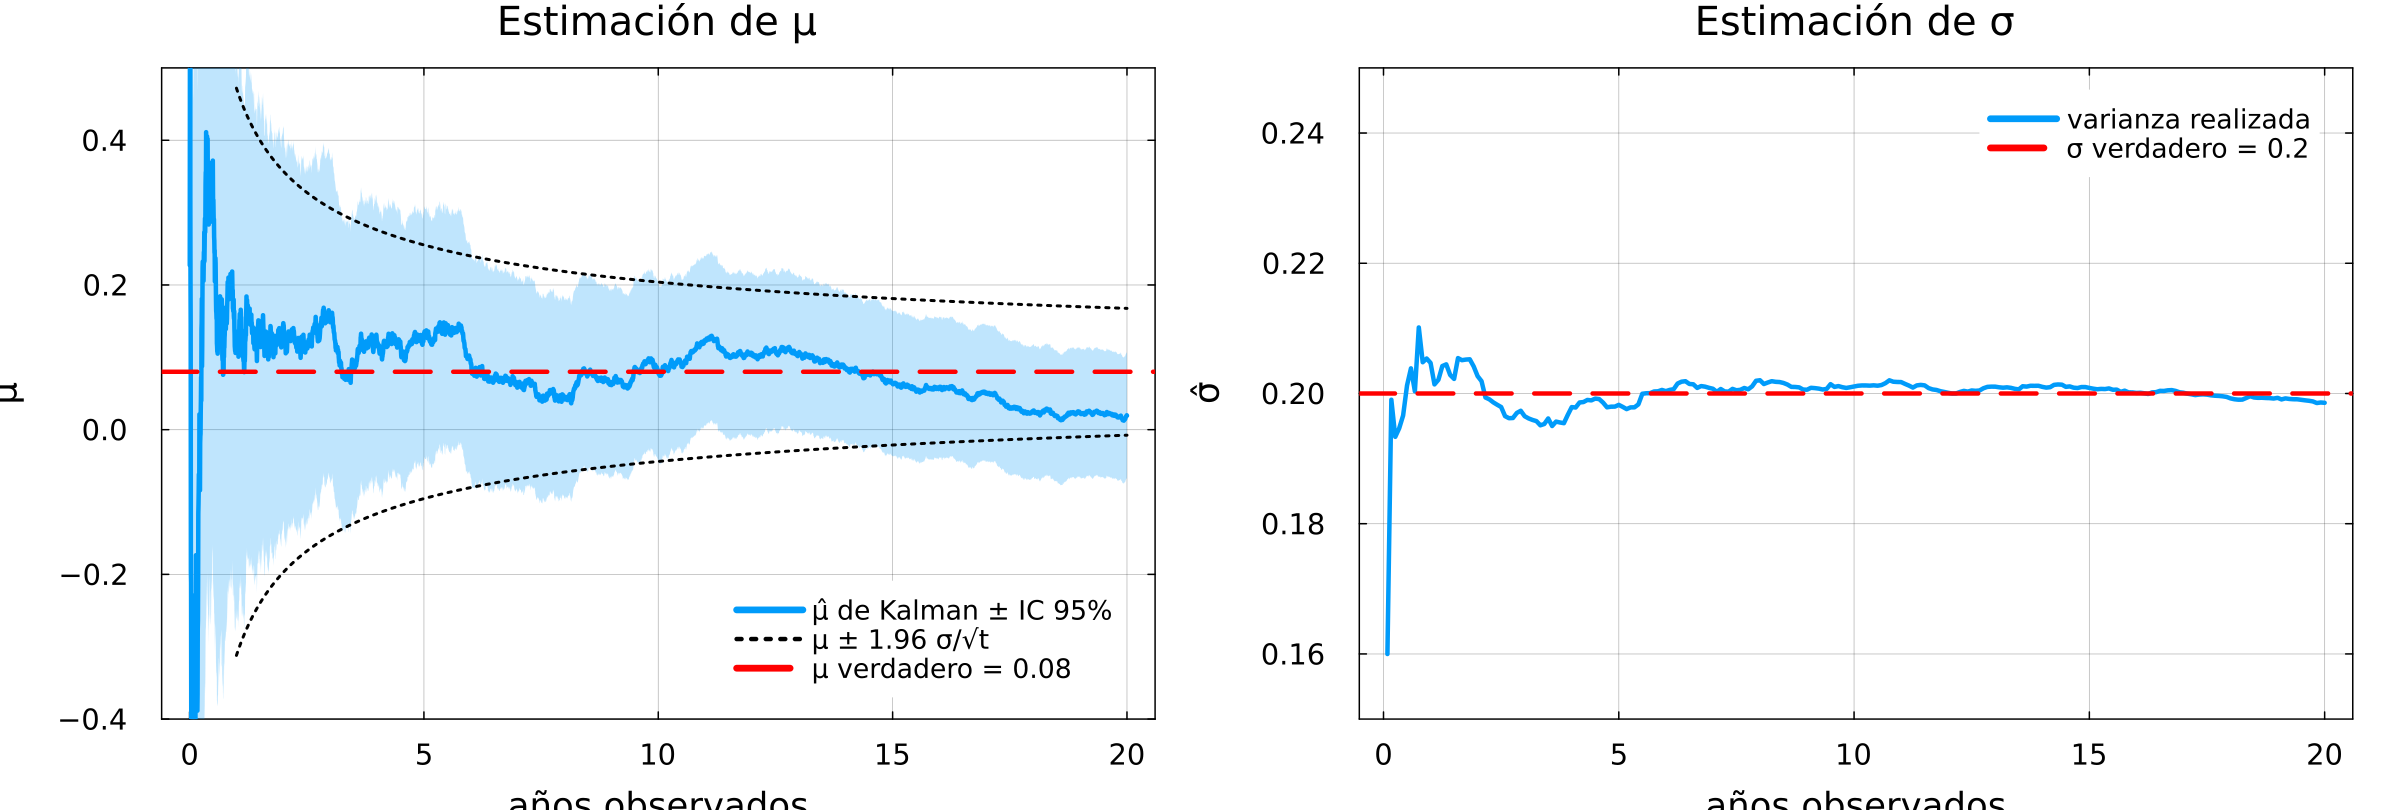

In [6]:
Random.seed!(3)
Tt, h = 20.0, 1/252
R = rendimientos(Tt, h)
m, Pk = kalman_mu(R, h, sigma_rv(R, h)^2)
t = h .* (1:length(R))
sig_hat = [sqrt(var(R[1:k])/h) for k in 21:21:length(R)]   # varianza realizada hasta cada mes

pa = plot(t, m, ribbon=1.96 .* sqrt.(Pk), fillalpha=0.25, label="μ̂ de Kalman ± IC 95%", ylims=(-0.4, 0.5),
          xlabel="años observados", ylabel="μ̂", title="Estimación de μ", legend=:bottomright)
plot!(pa, t[252:end], par.mu .+ 1.96 .* par.sigma ./ sqrt.(t[252:end]), color=:black, ls=:dot, lw=2, label="μ ± 1.96 σ/√t")
plot!(pa, t[252:end], par.mu .- 1.96 .* par.sigma ./ sqrt.(t[252:end]), color=:black, ls=:dot, lw=2, label=false)
hline!(pa, [par.mu], color=:red, ls=:dash, label="μ verdadero = 0.08")
pb = plot(t[21:21:end], sig_hat, label="varianza realizada", xlabel="años observados", ylabel="σ̂", ylims=(0.15, 0.25),
          title="Estimación de σ", legend=:topright)
hline!(pb, [par.sigma], color=:red, ls=:dash, label="σ verdadero = 0.2")
@printf("con 20 años: mu estimado = %.4f +- %.4f (IC 95%%),  sigma estimado = %.4f\n", m[end], 1.96*sqrt(Pk[end]), sig_hat[end])
savefig(plot(pa, dpi=300), "figuras_poster/kalman_estimacion_mu.png")
savefig(plot(pb, dpi=300), "figuras_poster/kalman_estimacion_sigma.png")
plot(pa, pb, layout=(1, 2), size=(1600, 540))

Con 20 años de datos diarios el filtro estima $\hat\mu=0.019$ con un intervalo de $\pm0.087$: el intervalo contiene al verdadero $\mu=0.08$, pero ni siquiera permite afirmar que $\mu>r=0.03$. La banda del filtro se angosta como $1/\sqrt t$, igual que la cota $\sigma/\sqrt t$ (punteada), y la estimación se mueve lentamente. En cambio, $\sigma$ queda estimado con un error menor que $0.01$ desde el primer año.

**Muchas trayectorias.** Repetimos el experimento 500 veces para varios horizontes $T$ y comparamos la desviación de los estimadores con las fórmulas de las Proposiciones 1.1 y 1.2.

In [7]:
Random.seed!(4)
Ts = [1, 2, 5, 10, 20, 40]; sd_mu = Float64[]; sd_sig = Float64[]
println("   T   media(mu)  sd(mu)  sigma/sqrt(T)   media(sigma)  sd(sigma)  sigma/sqrt(2n)")
for T in Ts
    est_mu = zeros(500); est_sig = zeros(500)
    for i in 1:500
        R = rendimientos(T, h)
        s = sigma_rv(R, h)
        est_mu[i] = kalman_mu(R, h, s^2)[1][end]; est_sig[i] = s
    end
    push!(sd_mu, std(est_mu)); push!(sd_sig, std(est_sig))
    @printf("%4d %10.4f %8.4f %12.4f %13.4f %10.5f %12.5f\n", T, mean(est_mu), sd_mu[end], par.sigma/sqrt(T),
            mean(est_sig), sd_sig[end], par.sigma/sqrt(2*T/h))
end

println("\nmisma ventana (T = 10 años), distinta frecuencia de observación:")
for (nombre, hf) in [("diaria", 1/252), ("semanal", 1/52), ("mensual", 1/12)]
    est_mu = zeros(1000); est_sig = zeros(1000)
    for i in 1:1000
        R = rendimientos(10, hf); s = sigma_rv(R, hf)
        est_mu[i] = kalman_mu(R, hf, s^2)[1][end]; est_sig[i] = s
    end
    @printf("  %-8s sd(mu) = %.4f   sd(sigma) = %.5f\n", nombre, std(est_mu), std(est_sig))
end

   T   media(mu)  sd(mu)  sigma/sqrt(T)   media(sigma)  sd(sigma)  sigma/sqrt(2n)
   1     0.0886   0.1988       0.2000        0.1997    0.00863      0.00891
   2     0.0772   0.1467       0.1414        0.2001    0.00604      0.00630
   5     0.0773   0.0923       0.0894        0.2000    0.00425      0.00398
  10     0.0787   0.0625       0.0632        0.2000    0.00280      0.00282
  20     0.0817   0.0444       0.0447        0.2000    0.00188      0.00199
  40     0.0795   0.0321       0.0316        0.2000    0.00140      0.00141

misma ventana (T = 10 años), distinta frecuencia de observación:
  diaria   sd(mu) = 0.0619   sd(sigma) = 0.00276
  semanal  sd(mu) = 0.0612   sd(sigma) = 0.00597
  mensual  sd(mu) = 0.0602   sd(sigma) = 0.01274


Las fórmulas se cumplen: la desviación de $\hat\mu$ coincide con $\sigma/\sqrt T$ y la de $\hat\sigma$ con $\sigma/\sqrt{2n}$, y ambos estimadores son insesgados (las medias de $\hat\mu$ fluctúan en torno a 0.08 dentro de su error). La diferencia entre los dos parámetros es enorme:

* con 10 años, $\hat\sigma$ tiene un error de 0.003 (1.4%), pero $\hat\mu$ tiene un error de 0.063, **mayor que la prima de riesgo** $\mu-r=0.05$;
* observar con más frecuencia (diario en vez de mensual) mejora $\hat\sigma$ unas 4.6 veces, pero **no mejora** $\hat\mu$, como dice la Proposición 1.2: para conocer $\mu$ hay que esperar, no muestrear más seguido.

Para que el error de $\hat\mu$ sea menor que la prima de riesgo con 95% de confianza, $1.96\,\sigma/\sqrt T<0.05$, harían falta más de 61 años de datos.

### 1.4 Deriva variable: filtro con $q>0$

Si $\mu$ cambia en el tiempo, el filtro con $q=0$ promedia toda la historia y no lo sigue. Con $q>0$ el filtro **olvida** los datos viejos: en régimen estacionario (versión continua del filtro, de Kalman–Bucy) la varianza es $P_\infty=\sigma\sqrt q$ y la memoria efectiva es de $\sigma/\sqrt q$ años. Hay un compromiso: poca memoria sigue los cambios pero con mucho ruido.

Lo probamos con un ciclo económico de 10 años, $\mu(t)=0.08+0.06\sin(2\pi t/10)$, midiendo el error cuadrático medio del seguimiento entre los años 10 y 40, para la volatilidad del proyecto ($\sigma=0.2$) y para una acción mucho menos volátil ($\sigma=0.05$).

                  q = 0e+00     q = 1e-04     q = 1e-03     q = 1e-02  
sigma = 0.20:        0.0586        0.0591        0.0686        0.1031     (memoria sigma/sqrt(q) = inf, 20.0, 6.3, 2.0 años)
sigma = 0.05:        0.0443        0.0436        0.0415        0.0521     (memoria sigma/sqrt(q) = inf, 5.0, 1.6, 0.5 años)


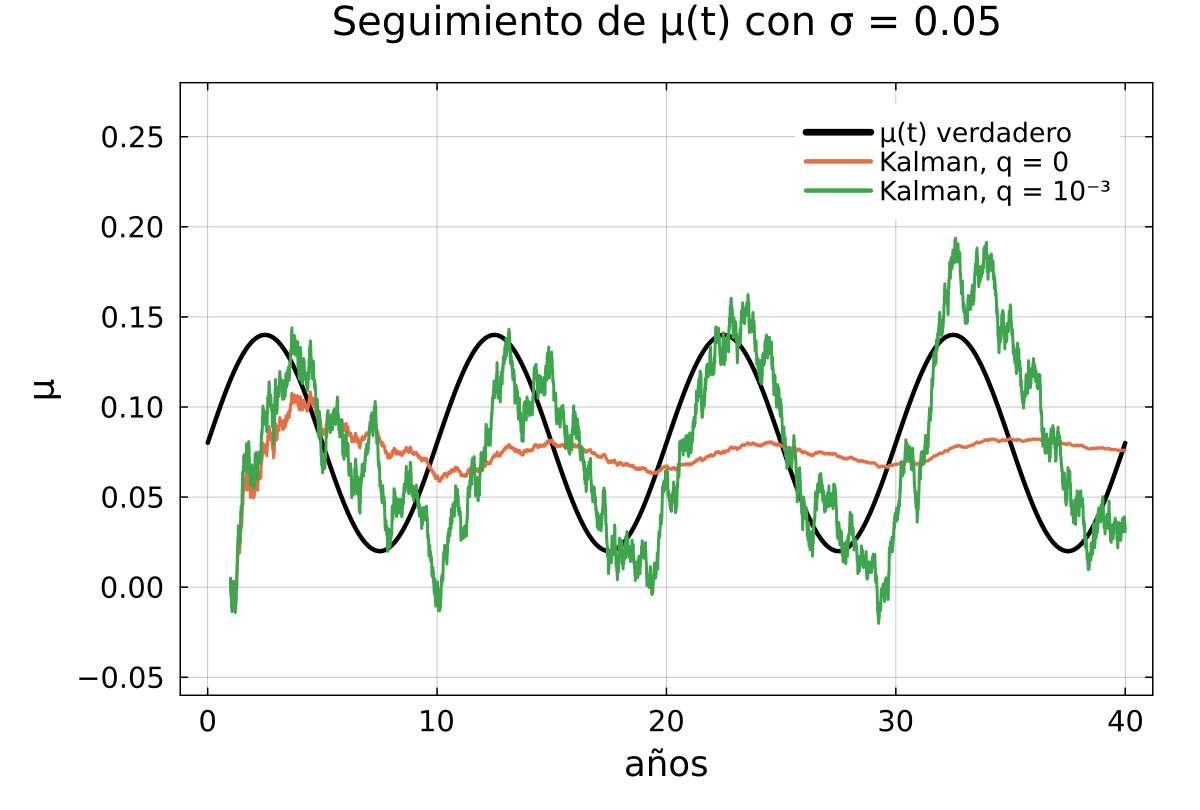

In [8]:
mu_ciclo(t) = 0.08 + 0.06*sin(2π*t/10)
qs = [0.0, 1e-4, 1e-3, 1e-2]
Random.seed!(5)
println("               ", join([@sprintf("   q = %-7.0e", q) for q in qs]))
for sig in [0.20, 0.05]
    err = zeros(length(qs))
    for rep in 1:50
        R = rendimientos(40, h; mu=mu_ciclo, sigma=sig); s2 = var(R)/h
        tt = h .* (1:length(R)); I = tt .>= 10
        for (j, q) in enumerate(qs)
            mq, _ = kalman_mu(R, h, s2; q=q)
            err[j] += sqrt(mean((mq[I] .- mu_ciclo.(tt[I])).^2))/50
        end
    end
    @printf("sigma = %.2f:  %s   (memoria sigma/sqrt(q) = %s años)\n", sig, join([@sprintf("  %10.4f  ", e) for e in err]),
            join([q > 0 ? @sprintf("%.1f", sig/sqrt(q)) : "inf" for q in qs], ", "))
end

# una trayectoria con sigma = 0.05 para ver el seguimiento
Random.seed!(6)
R = rendimientos(40, h; mu=mu_ciclo, sigma=0.05); tt = h .* (1:length(R))
pl = plot(tt, mu_ciclo.(tt), color=:black, label="μ(t) verdadero", xlabel="años", ylabel="μ", ylims=(-0.06, 0.28),
          title="Seguimiento de μ(t) con σ = 0.05", legend=:topright)
I1 = tt .>= 1                                           # desde el año 1, sin el transiente inicial del filtro
for (q, nombre) in [(0.0, "Kalman, q = 0"), (1e-3, "Kalman, q = 10⁻³")]
    plot!(pl, tt[I1], kalman_mu(R, h, var(R)/h; q=q)[1][I1], lw=2, label=nombre)
end
savefig(plot(pl, dpi=300), "figuras_poster/kalman_seguimiento.png")
pl

Con la volatilidad del proyecto ($\sigma=0.2$), ningún $q>0$ mejora al filtro de deriva constante: con memoria corta domina el ruido, y con memoria larga el filtro se comporta como el de $q=0$, que estima el promedio 0.08 y deja un error del orden de la amplitud del ciclo dividida por $\sqrt2$ (0.042), más el error de estimación. Incluso con $\sigma=0.05$ la mejora es pequeña (de 0.044 a 0.042 con $q=10^{-3}$), y en el gráfico el filtro sigue al ciclo con retraso y mucho ruido. Es otra cara de la Proposición 1.2: la información sobre $\mu$ llega a razón de $1/\sigma^2$ por año, y un ciclo de 10 años no da tiempo para aprenderlo.

### 1.5 Efecto en el control: Merton con parámetros estimados

Un inversionista que observó $T_{\text{obs}}$ años de precios usa en la fórmula de Merton los parámetros estimados:
$$
\hat\Pi=\frac{\hat\mu-r}{\eta\hat\sigma^2},\qquad \hat\nu=\frac1\eta\Big[\gamma-(1-\eta)\Big(r+\frac{\hat\theta^2}{2\eta}\Big)\Big],\qquad \hat\theta=\frac{\hat\mu-r}{\hat\sigma}.
$$
Es una estrategia proporcional, así que su valor **verdadero** se calcula exactamente con la Prop. 2 del avance 2 (con los $\mu$ y $\sigma$ verdaderos) y se compara con el óptimo en capital equivalente $x_{CE}$. Si $\kappa(\hat\Pi,\hat\nu)\le0$, la estrategia vale $J=-\infty$ ($x_{CE}=0$): con $\eta=2$ esto pasa cuando $\hat\mu$ sale muy alto, porque el inversionista se apalanca demasiado **y** consume demasiado.

Comparamos con una versión **prudente**, que acota la fracción a $[0,1]$ (sin apalancamiento ni venta corta, como en la Sección 2) y usa la tasa de consumo óptima para esa fracción con los parámetros estimados, $\tilde\nu=\frac{\gamma+(\eta-1)\hat\rho(\tilde\Pi)}{\eta}$ con $\hat\rho(p)=r+(\hat\mu-r)p-\frac\eta2\hat\sigma^2p^2$. La referencia es invertir todo en el banco con su consumo óptimo, que equivale a $x_{CE}=70$ (Sección 2).

In [9]:
Random.seed!(7)
Tobs = [5, 10, 20, 40]; med_ingenuo = Float64[]; med_prudente = Float64[]
println("Tobs  sd(Pi est.)  mediana xCE  P(J = -Inf)  P(xCE < 70)  |  prudente: mediana xCE  P(xCE < 70)")
for To in Tobs
    x1 = zeros(2000); x2 = zeros(2000); Pis = zeros(2000)
    for i in 1:2000
        R = rendimientos(To, h)
        s2 = var(R)/h
        mu_e = kalman_mu(R, h, s2)[1][end]
        th = (mu_e - par.r)/sqrt(s2)
        Pi_e = (mu_e - par.r)/(par.eta*s2)
        nu_e = (par.gamma - (1 - par.eta)*(par.r + th^2/(2*par.eta)))/par.eta
        Pis[i] = Pi_e; x1[i] = xCE(Jexacto(Pi_e, nu_e))
        Pi_p = clamp(Pi_e, 0.0, 1.0)                                        # versión prudente
        nu_pr = (par.gamma + (par.eta - 1)*(par.r + (mu_e - par.r)*Pi_p - 0.5*par.eta*s2*Pi_p^2))/par.eta
        x2[i] = xCE(Jexacto(Pi_p, nu_pr))
    end
    push!(med_ingenuo, median(x1)); push!(med_prudente, median(x2))
    @printf("%4d %11.3f %12.2f %12.3f %12.3f  | %21.2f %12.3f\n", To, std(Pis), median(x1), mean(x1 .== 0), mean(x1 .< 70),
            median(x2), mean(x2 .< 70))
end

Tobs  sd(Pi est.)  mediana xCE  P(J = -Inf)  P(xCE < 70)  |  prudente: mediana xCE  P(xCE < 70)
   5       1.099        27.30        0.426        0.652  |                 69.99        0.626
  10       0.770        71.54        0.238        0.488  |                 73.97        0.453
  20       0.558        85.64        0.116        0.341  |                 85.64        0.299
  40       0.386        92.61        0.031        0.191  |                 92.61        0.149


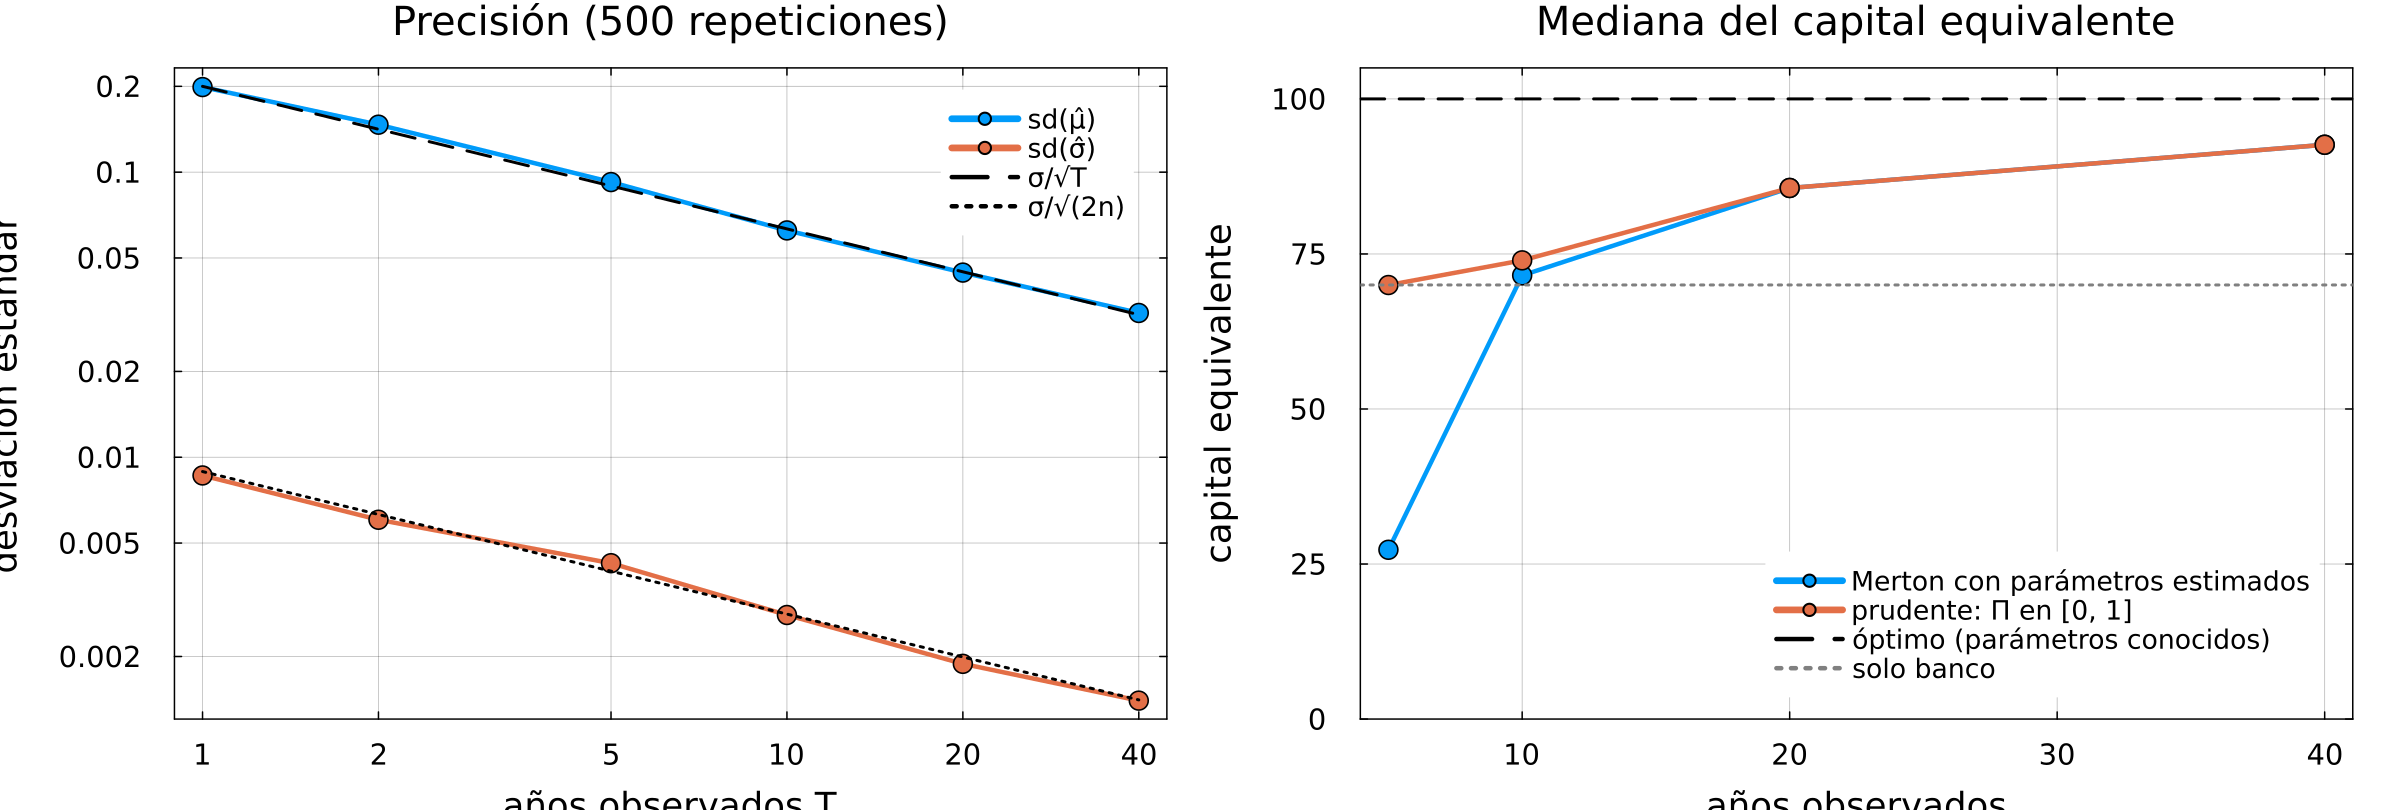

In [10]:
# figura del reporte: aprendizaje de mu, precisión de los estimadores y costo en el control
pc = plot(Ts, [sd_mu sd_sig], xscale=:log10, yscale=:log10, marker=:circle, xlabel="años observados T",
          ylabel="desviación estándar", label=["sd(μ̂)" "sd(σ̂)"], title="Precisión (500 repeticiones)", legend=:topright,
          xticks=(Ts, string.(Ts)),
          yticks=([0.002, 0.005, 0.01, 0.02, 0.05, 0.1, 0.2], ["0.002", "0.005", "0.01", "0.02", "0.05", "0.1", "0.2"]))
plot!(pc, Ts, par.sigma ./ sqrt.(Ts), ls=:dash, color=:black, lw=2, label="σ/√T")
plot!(pc, Ts, par.sigma ./ sqrt.(2 .* Ts ./ h), ls=:dot, color=:black, lw=2, label="σ/√(2n)")
pd = plot(Tobs, [med_ingenuo med_prudente], marker=:circle, xlabel="años observados", ylabel="capital equivalente",
          ylims=(0, 105), label=["Merton con parámetros estimados" "prudente: Π en [0, 1]"],
          title="Mediana del capital equivalente", legend=:bottomright)
hline!(pd, [100], color=:black, ls=:dash, lw=2, label="óptimo (parámetros conocidos)")
hline!(pd, [70], color=:gray, ls=:dot, lw=2, label="solo banco")
savefig(plot(pc, dpi=300), "figuras_poster/kalman_precision.png")
savefig(plot(pd, dpi=300), "figuras_poster/kalman_costo_control.png")
display(plot(pc, pd, layout=(1, 2), size=(1600, 540)))

# para el reporte, los tres paneles juntos con letras más chicas
fig = plot(pa, pc, pd, layout=(1, 3), size=(1200, 340), titlefontsize=10, guidefontsize=9, tickfontsize=8,
           legendfontsize=7, bottom_margin=6Plots.mm, left_margin=3Plots.mm)
mkpath("figuras_final"); savefig(fig, "figuras_final/kalman_merton.pdf");

El costo de no conocer los parámetros es grande:

* con 5 años de datos, la mediana del capital equivalente es 27 (como perder el 73% del capital), el 43% de los inversionistas obtiene $J=-\infty$ y el 65% queda peor que si hubiera dejado todo en el banco;
* con 10 años la mediana (72) apenas supera al banco (70), y recién con 40 años se llega a 93.

La versión prudente, que no se apalanca ni vende corto, evita los peores casos: con 5 años su mediana es la del banco, porque cuando $\hat\mu<r$ no invierte. Con 20 años o más ambas tienen la misma mediana, porque la cota casi no se activa.

En resumen, el filtro de Kalman alcanza la mejor precisión posible para $\mu$, pero esa precisión no basta para usar la fórmula de Merton tal cual: la incertidumbre sobre $\mu$ es la principal limitación práctica del modelo.

### 1.6 Conclusiones y pendientes

**Conclusiones.**
1. La volatilidad $\sigma$ se estima con la varianza realizada, con error $\sigma/\sqrt{2n}$: depende del número de observaciones y es pequeño con datos diarios.
2. El filtro de Kalman para $\mu$ con deriva constante es el estimador de máxima verosimilitud y alcanza la cota $\sigma/\sqrt T$, que depende solo del tiempo observado: con 10 años el error es mayor que la prima de riesgo.
3. Con $q>0$ el filtro puede seguir una deriva variable, pero con $\sigma=0.2$ no mejora al de deriva constante.
4. Usar en el control de Merton los parámetros estimados cuesta mucho: con 10 años de datos la mediana del capital equivalente es 72, y en una cuarta parte de los casos $J=-\infty$. Acotar la fracción a $[0,1]$ reduce las pérdidas.

**Pendientes.**
* Resolver el problema con **información parcial**: tratar la salida del filtro $\hat\mu_t$ como un estado más y resolver la HJB en $(x,\hat\mu)$, para que el control tome en cuenta la incertidumbre en vez de usar $\hat\mu$ como si fuera exacto.
* Estimar una volatilidad que cambia en el tiempo (volatilidad estocástica), lo que requiere un filtro no lineal, por ejemplo de partículas.
* Probar el filtro con precios reales de una acción o de un índice.

## 2. Existencia, HJB numérica y controles restringidos (objetivos 4, 5 y 6)

Completar lo que el reporte de avances dejó pendiente en la parte de programación dinámica:

* **Objetivo 5:** caracterizar el control óptimo resolviendo **numéricamente** la ecuación HJB, sin usar la fórmula de Merton, y comparar con $(\Pi^*,\nu)$ (Secciones 2.1 a 2.3).
* **Objetivo 4:** ver numéricamente la existencia del control óptimo: la iteración de políticas construye controles admisibles cuyo valor sube hasta $V$, y la condición $\nu>0$ separa los casos con y sin óptimo (Sección 2.4).
* **Objetivo 6:** estudiar qué pasa al **restringir los controles admisibles**: fracción acotada $\Pi_t\in[\Pi_{\min},\Pi_{\max}]$, y controles markovianos frente a no markovianos (Sección 2.5).

Usamos lo demostrado en el reporte de avances (HJB, solución explícita y su optimalidad) y la fórmula exacta de $J$ para estrategias proporcionales (Prop. 2 del avance 2).

### 2.1 La HJB en coordenada logarítmica y la condición de borde

**Cambio de variable.** El capital vive en varias escalas (de 1 a 10 000), así que trabajamos en $y=\log x$ con $W(y)=V(e^y)$. Como $V'=e^{-y}W'$ y $V''=e^{-2y}(W''-W')$, y escribiendo el consumo como tasa $e=c/x$, la HJB queda
$$
\gamma W=\sup_{\Pi\in[\Pi_{\min},\Pi_{\max}],\ e\ge0}\Big\{U(e\,e^{y})+b(\Pi,e)\,W'+a(\Pi)\,W''\Big\},\qquad b=r+\Pi(\mu-r)-e-\tfrac12\sigma^2\Pi^2,\quad a=\tfrac12\sigma^2\Pi^2. \tag{HJB-log}
$$
La difusión $a$ ya no depende del estado, y una malla uniforme en $y$ es geométrica en $x$. Dejamos el intervalo de la fracción como parámetro para la Sección 2.5 ($\Pi_{\min}=-\infty$, $\Pi_{\max}=+\infty$ es el problema sin restricción).

**Proposición 2.1 (homotecia).** Para todo $\lambda>0$, $V(\lambda x)=\lambda^{1-\eta}V(x)+\frac{\lambda^{1-\eta}-1}{(1-\eta)\gamma}$. En consecuencia
$$
W'(y)=(1-\eta)W(y)+\frac1\gamma,\qquad W''(y)=(1-\eta)W'(y).
$$

*Demostración.* Si $(\Pi,C)$ es admisible desde $x$, entonces $(\Pi,\lambda C)$ es admisible desde $\lambda x$ y su capital es $\lambda X$, porque la ecuación es lineal en $(X,C)$. Como $U(\lambda c)=\lambda^{1-\eta}U(c)+\frac{\lambda^{1-\eta}-1}{1-\eta}$, se tiene $J(\lambda x;\Pi,\lambda C)=\lambda^{1-\eta}J(x;\Pi,C)+\frac{\lambda^{1-\eta}-1}{(1-\eta)\gamma}$, y tomando supremo (la correspondencia $C\leftrightarrow\lambda C$ es biyectiva) se obtiene la igualdad. Derivando en $\lambda=1$ queda $xV'(x)=(1-\eta)V(x)+\frac1\gamma$, que en $y$ es la primera identidad; derivándola se obtiene la segunda. $\blacksquare$

La proposición usa solo la estructura del problema (dinámica lineal y utilidad homogénea), **no** la fórmula de $V$, y sigue valiendo si la fracción se restringe a un intervalo.

**Condición de borde.** En los extremos de la malla faltan vecinos para aproximar $W'$ y $W''$, así que usamos la Proposición 2.1. Reemplazándola en (HJB-log) para una política fija $(\Pi,e)$ queda
$$
\big[\gamma-(1-\eta)\big(b+(1-\eta)a\big)\big]W=U(e\,e^{y})+\frac{b+(1-\eta)a}{\gamma},
$$
y como $b+(1-\eta)a=r+\Pi(\mu-r)-e-\frac\eta2\sigma^2\Pi^2$, el corchete es exactamente $\kappa(\Pi,e)$: **el valor en el borde es el de mantener para siempre la política proporcional del borde**, $W=J(e^y;\Pi,e)$ (Prop. 2 del avance 2). Así el borde no necesita conocer $V$.

### 2.2 Esquema numérico: diferencias *upwind* e iteración de políticas

En la malla $y_i=y_1+(i-1)k$, $i=1,\dots,n$, aproximamos $W'$ con diferencias hacia adelante si $b\ge0$ y hacia atrás si $b<0$ (*upwind*), y $W''$ con diferencias centradas. Para una política fija queda el sistema tridiagonal
$$
\Big(\gamma+\frac{b^++b^-}{k}+\frac{2a}{k^2}\Big)W_i-\Big(\frac{b^+}{k}+\frac{a}{k^2}\Big)W_{i+1}-\Big(\frac{b^-}{k}+\frac{a}{k^2}\Big)W_{i-1}=U(e_i\,e^{y_i}),\qquad b^\pm=\max(\pm b,0).
$$
Los coeficientes fuera de la diagonal son $\le0$ y la diagonal domina estrictamente gracias a $\gamma>0$: es una **M-matriz**, así que el sistema tiene solución única y el esquema es **monótono**. Es la aproximación por cadenas de Markov de [KD]: dividiendo por la diagonal, los coeficientes de $W_{i\pm1}$ son las probabilidades de saltar a un nodo vecino multiplicadas por un factor de descuento, y la monotonía es lo que garantiza la convergencia a la solución de la HJB.

**Iteración de políticas (Howard).** Partimos de la política "todo en el banco y consumir los intereses", $\Pi=0$, $e=r$ (el capital queda constante y $\kappa=\gamma>0$), y repetimos:
1. *evaluación:* resolver el sistema lineal para la política actual, lo que da $W^{(m)}$;
2. *mejora:* en cada nodo, maximizar el lado derecho de (HJB-log) con las derivadas de $W^{(m)}$ (diferencias centradas). Las condiciones de primer orden dan
$$
e=\Big(\frac{e^{(1-\eta)y}}{W'}\Big)^{1/\eta},\qquad \Pi=\mathrm{proy}_{[\Pi_{\min},\Pi_{\max}]}\Big(-\frac{(\mu-r)W'}{\sigma^2(W''-W')}\Big),
$$
porque $U$ es cóncava y el término en $\Pi$ es una parábola cóncava cuando $W''<W'$.

**Proposición 2.2 (Howard).** Si en la mejora se maximiza el lado derecho discreto, los valores son crecientes, $W^{(1)}\le W^{(2)}\le\cdots$, y convergen a la solución del esquema [KD], [CRRA, Lema de Howard]. Cada $W^{(m)}$ es el valor de un control de retroalimentación markoviano admisible, así que el método **construye** controles cada vez mejores. Nosotros usamos las condiciones de primer orden con diferencias centradas, que es más simple; en la Sección 2.4 se ve que igual los valores crecen.

In [11]:
# Resuelve (HJB-log) en la malla uniforme y, por iteración de políticas (Howard).
# Devuelve W, la política (Pi, e) en cada nodo y el valor en x0 de cada iteración.
function resolver_hjb(y; P=par, Pimin=-5.0, Pimax=5.0, tol=1e-10, maxit=100)
    n = length(y); k = y[2] - y[1]; x = exp.(y)
    i0 = argmin(abs.(x .- P.x0))                       # nodo de x0
    Pi = fill(0.0, n); e = fill(P.r, n)                 # política inicial: banco, consumir los intereses
    W = zeros(n); historial = Float64[]
    for it in 1:maxit
        # 1. evaluación: sistema tridiagonal con upwind
        b = P.r .+ Pi .* (P.mu - P.r) .- e .- 0.5*P.sigma^2 .* Pi.^2
        a = 0.5*P.sigma^2 .* Pi.^2
        bp, bm = max.(b, 0), max.(-b, 0)
        dl = -(bm ./ k .+ a ./ k^2)                     # coeficiente de W[i-1]
        d  = P.gamma .+ (bp .+ bm) ./ k .+ 2a ./ k^2    # coeficiente de W[i]
        du = -(bp ./ k .+ a ./ k^2)                     # coeficiente de W[i+1]
        rhs = U.(e .* x; P=P)
        for i in (1, n)                                 # bordes: Prop. 2.1 (homotecia)
            dl[i] = 0.0; du[i] = 0.0
            d[i] = kappa(Pi[i], e[i]; P=P)
            rhs[i] = U(e[i]*x[i]; P=P) + (b[i] + (1 - P.eta)*a[i])/P.gamma
        end
        Wn = Tridiagonal(dl[2:n], d, du[1:n-1]) \ rhs
        push!(historial, Wn[i0])
        # 2. mejora: condiciones de primer orden con diferencias centradas
        W1, W2 = similar(Wn), similar(Wn)
        for i in 2:n-1
            W1[i] = (Wn[i+1] - Wn[i-1])/(2k)
            W2[i] = (Wn[i+1] - 2Wn[i] + Wn[i-1])/k^2
        end
        for i in (1, n)                                 # en los bordes, Prop. 2.1
            W1[i] = (1 - P.eta)*Wn[i] + 1/P.gamma
            W2[i] = (1 - P.eta)*W1[i]
        end
        W1 = max.(W1, 1e-12)                            # V es creciente: W' > 0
        e = (x .^ (1 - P.eta) ./ W1) .^ (1/P.eta)
        den = P.sigma^2 .* (W2 .- W1)
        Pi = [den[i] < 0 ? clamp(-(P.mu - P.r)*W1[i]/den[i], Pimin, Pimax) : Pimax for i in 1:n]
        cambio = maximum(abs.(Wn .- W))/maximum(abs.(Wn))
        W = Wn
        cambio < tol && break
    end
    return (W=W, Pi=Pi, e=e, x=x, historial=historial)
end

resolver_hjb (generic function with 1 method)

### 2.3 Validación contra la solución exacta (objetivo 5)

Malla en $x\in[1,10^4]$ con $n$ impar, de modo que $x_0=100$ es el nodo central. Medimos el error de los controles en $x\in[5,2000]$ y el error en $V(x_0)$, también en capital equivalente, $x_{CE}(W(x_0))-x_0$, que está en las mismas unidades que el capital.

In [12]:
println("    n  iter  max|Pi - Pi*|  max|e - nu|  W(x0) - V(x0)  xCE - x0  tiempo")
ns = [101, 201, 401, 801, 1601, 3201]; errV = Float64[]
for n in ns
    y = collect(range(log(1.0), log(1e4), length=n))
    t = @elapsed s = resolver_hjb(y)
    I = (s.x .>= 5) .& (s.x .<= 2000); i0 = (n + 1) ÷ 2
    push!(errV, s.W[i0] - V(par.x0))
    @printf("%5d %5d %14.2e %12.2e %14.2e %9.4f %6.2fs\n", n, length(s.historial),
            maximum(abs.(s.Pi[I] .- Pistar())), maximum(abs.(s.e[I] .- nustar())), errV[end], xCE(s.W[i0]) - par.x0, t)
end
println("orden de convergencia en V(x0): ", join([@sprintf("%.2f", log2(errV[j]/errV[j+1])) for j in 1:length(ns)-1], ", "))

    n  iter  max|Pi - Pi*|  max|e - nu|  W(x0) - V(x0)  xCE - x0  tiempo
  101     8       6.55e-04     1.67e-04      -2.43e-02   -0.5523   1.80s
  201     8       2.80e-04     7.46e-05      -1.20e-02   -0.2730   0.00s
  401     7       1.24e-04     3.50e-05      -5.95e-03   -0.1359   0.00s
  801     7       5.79e-05     1.70e-05      -2.97e-03   -0.0678   0.00s
 1601     7       2.80e-05     8.34e-06      -1.48e-03   -0.0339   0.01s
 3201     6       1.37e-05     4.13e-06      -7.41e-04   -0.0169   0.01s
orden de convergencia en V(x0): 1.02, 1.01, 1.00, 1.00, 1.00


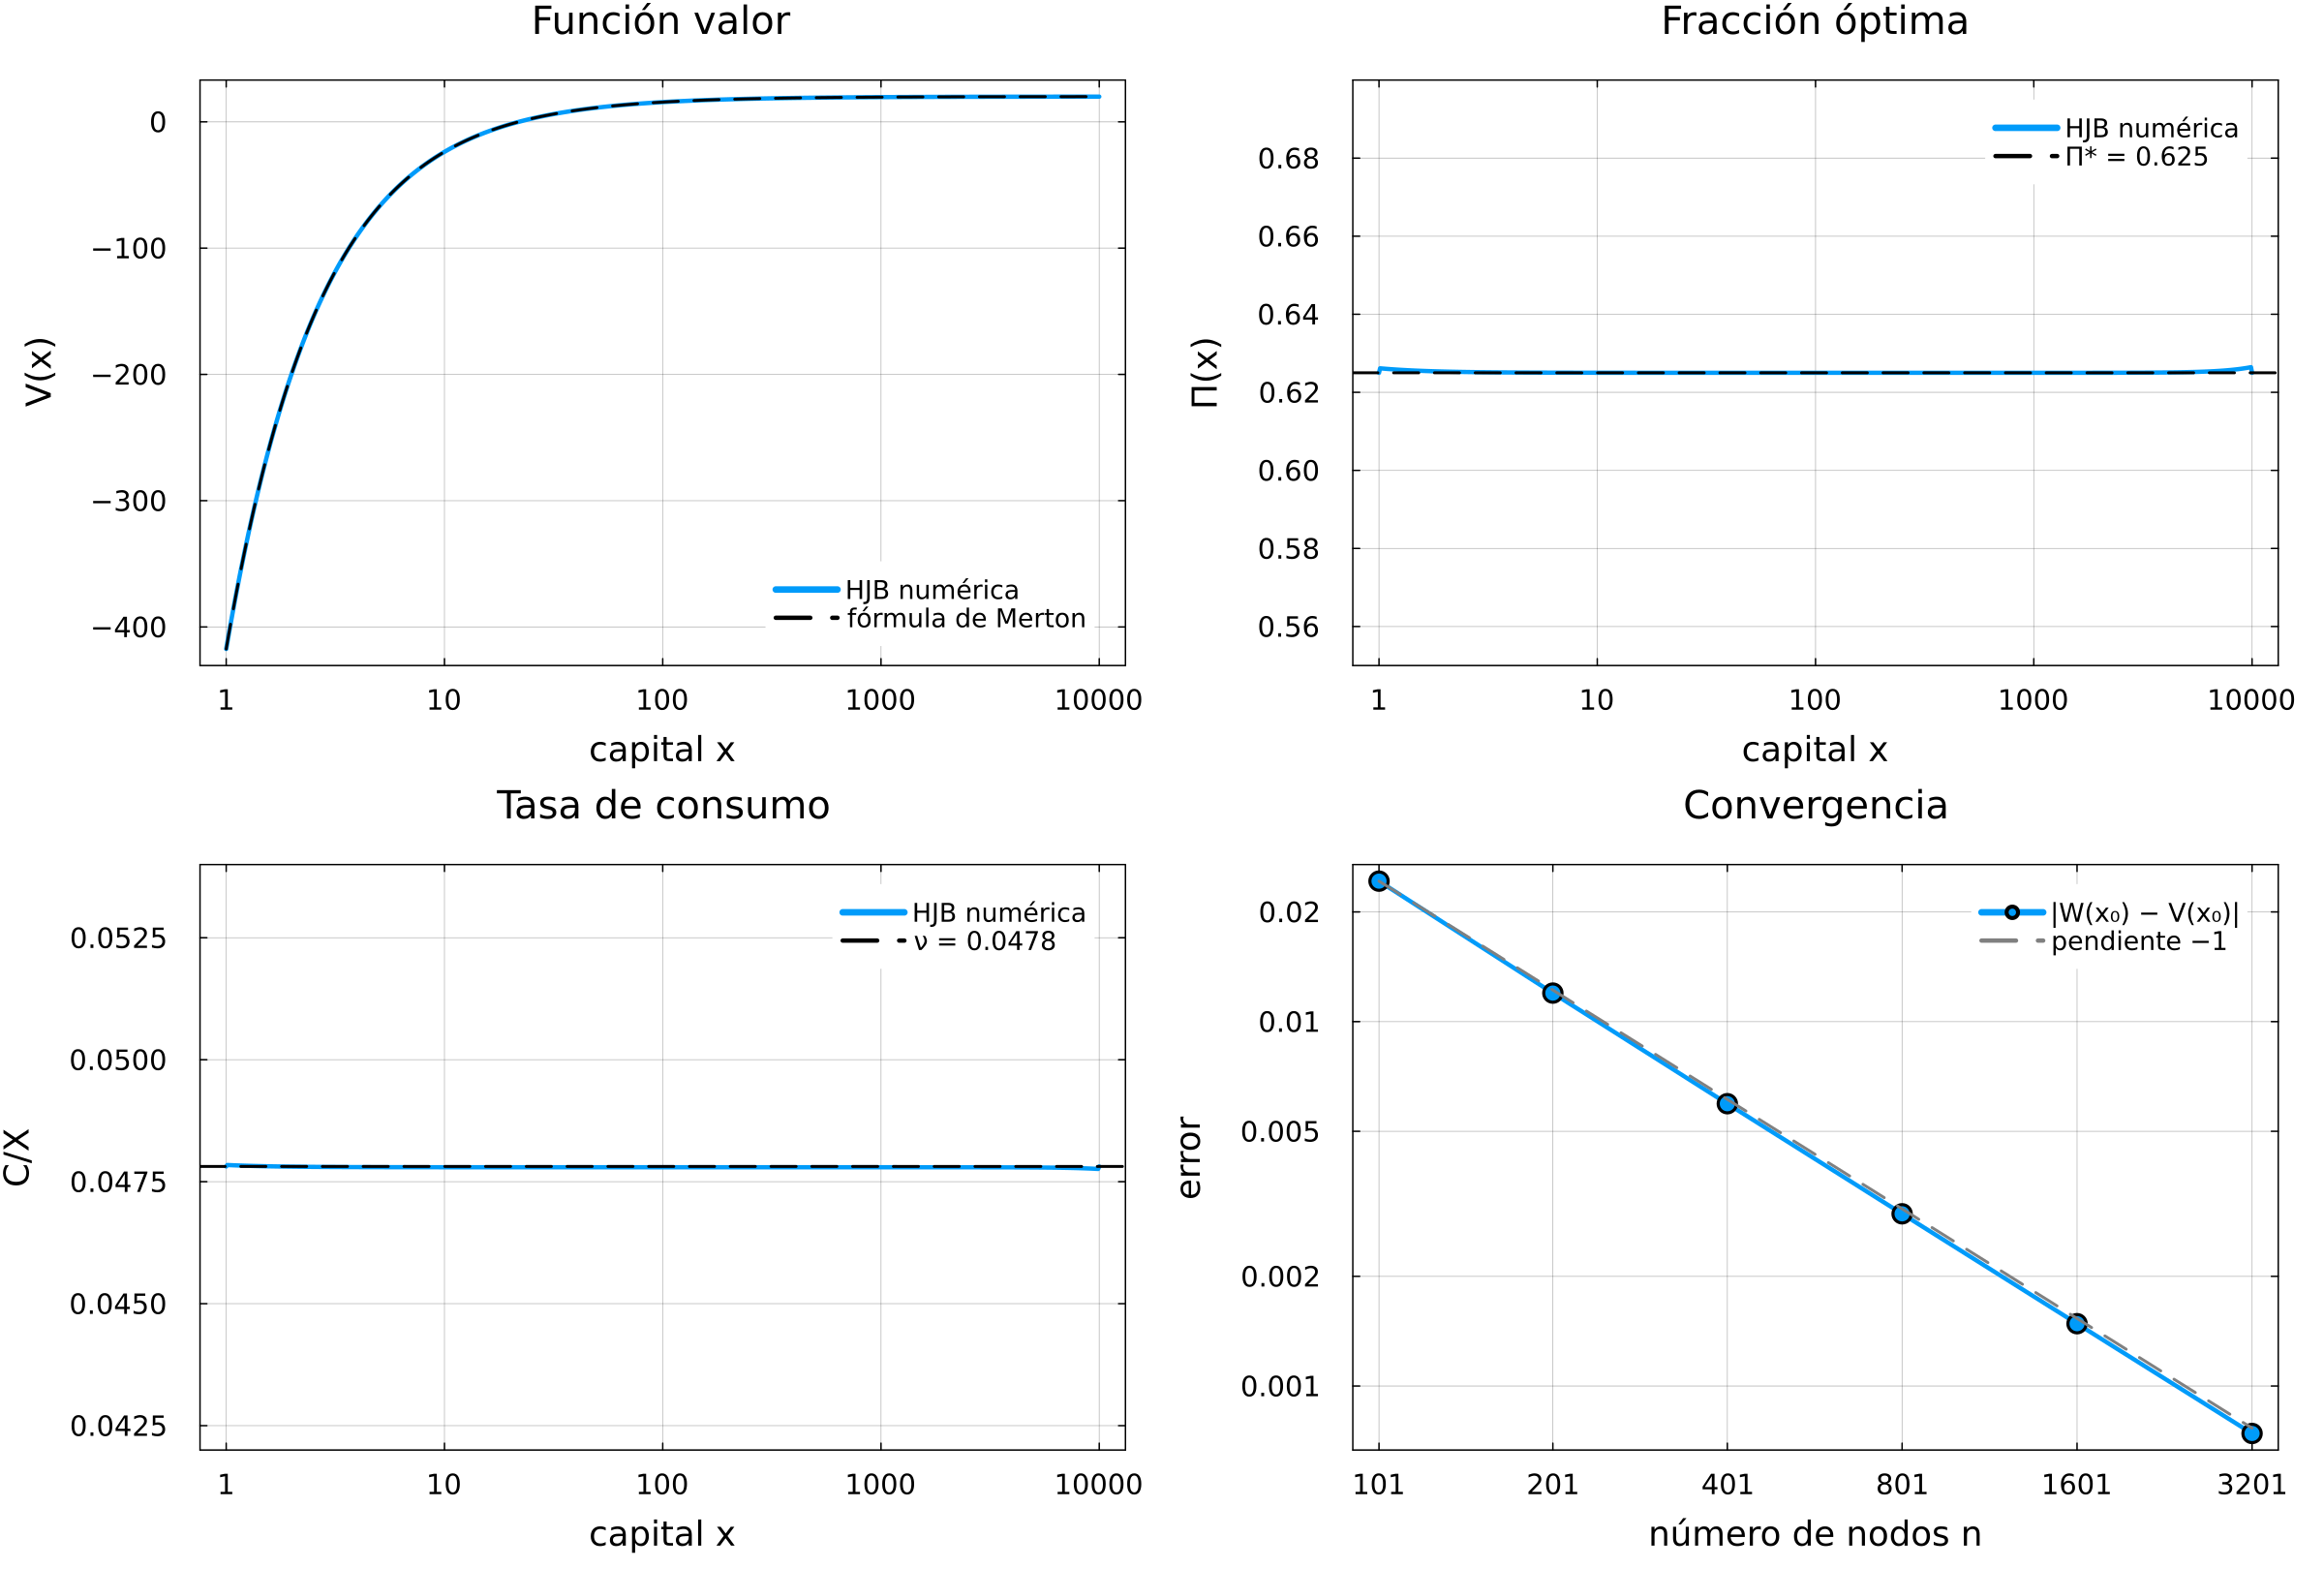

In [13]:
y = collect(range(log(1.0), log(1e4), length=801)); s = resolver_hjb(y)
ejex = ([1, 10, 100, 1000, 10000], ["1", "10", "100", "1000", "10000"])   # marcas del eje x en escala log
p1 = plot(s.x, s.W, xscale=:log10, label="HJB numérica", title="Función valor", xlabel="capital x", ylabel="V(x)",
          legend=:bottomright, xticks=ejex)
plot!(p1, s.x, V.(s.x), ls=:dash, color=:black, lw=2, label="fórmula de Merton")
p2 = plot(s.x, s.Pi, xscale=:log10, label="HJB numérica", title="Fracción óptima", xlabel="capital x", ylabel="Π(x)",
          ylims=(0.55, 0.7), xticks=ejex)
hline!(p2, [Pistar()], ls=:dash, color=:black, lw=2, label="Π* = 0.625")
p3 = plot(s.x, s.e, xscale=:log10, label="HJB numérica", title="Tasa de consumo", xlabel="capital x", ylabel="C/X",
          ylims=(0.042, 0.054), xticks=ejex)
hline!(p3, [nustar()], ls=:dash, color=:black, lw=2, label="ν = 0.0478")
p4 = plot(ns, abs.(errV), xscale=:log10, yscale=:log10, marker=:circle, label="|W(x₀) − V(x₀)|",
          title="Convergencia", xlabel="número de nodos n", ylabel="error", xticks=(ns, string.(ns)),
          yticks=([1e-3, 2e-3, 5e-3, 1e-2, 2e-2], ["0.001", "0.002", "0.005", "0.01", "0.02"]))
plot!(p4, ns, abs(errV[1]) .* ns[1] ./ ns, ls=:dash, color=:gray, lw=2, label="pendiente −1")
for (p, nombre) in [(p1, "valor"), (p2, "fraccion"), (p3, "consumo"), (p4, "convergencia")]
    savefig(plot(p, dpi=300), "figuras_poster/hjb_$nombre.png")
end

# para el reporte, los cuatro paneles en una fila con letras más chicas
fig = plot(p1, p2, p3, p4, layout=(1, 4), size=(1150, 300), titlefontsize=10, guidefontsize=9, tickfontsize=7,
           legendfontsize=7, bottom_margin=7Plots.mm, left_margin=3Plots.mm)
mkpath("figuras_final"); savefig(fig, "figuras_final/hjb_merton.pdf")
plot(p1, p2, p3, p4, layout=(2, 2), size=(1600, 1080))

El esquema converge con **orden 1** en $V(x_0)$ (el error se divide por dos al duplicar $n$), que es lo esperado de un esquema *upwind*: se elige porque es monótono, a costa de ser de primer orden. Con 801 nodos, el error en $V(x_0)$ equivale a perder 0.07 de capital sobre 100, y los controles numéricos son constantes en $x$ e iguales a $\Pi^*=0.625$ y $\nu=0.0478$ hasta $\sim10^{-5}$: la HJB numérica **reproduce la solución de Merton sin usarla**. La iteración de políticas converge en 6 a 8 iteraciones, cada una con un solo sistema tridiagonal, así que todo toma milisegundos.

### 2.4 Existencia vista numéricamente (objetivo 4)

**Iteraciones de Howard.** Cada iteración es el valor de un control markoviano admisible, así que $W^{(m)}(x_0)\le V(x_0)$ (salvo el error de malla), y la sucesión sube hasta el valor óptimo. La política límite es el maximizador de la HJB, que por el teorema de verificación del reporte (§1.5) es el control óptimo.

In [14]:
y = collect(range(log(1.0), log(1e4), length=801)); s = resolver_hjb(y)
println(" iteración      W(x0)      xCE")
for (m, w) in enumerate(s.historial)
    @printf("%6d %13.5f %9.3f\n", m, w, xCE(w))
end
@printf(" exacto  %13.5f %9.3f\n", V(par.x0), par.x0)

 iteración      W(x0)      xCE
     1      13.33333    65.616
     2      15.45509    96.248
     3      15.62067    99.887
     4      15.62264    99.932
     5      15.62265    99.932
     6      15.62265    99.932
     7      15.62265    99.932
 exacto       15.62561   100.000


**¿Qué pasa al variar $\eta$?** El teorema de existencia del reporte pide $\nu>0$, que siempre se cumple si $\eta\ge1$. Si $\eta<1$, la condición es $\gamma>(1-\eta)\big(r+\frac{\theta^2}{2\eta}\big)$, que falla cuando el inversionista tolera mucho riesgo: entonces $V=+\infty$ y no hay control óptimo (siempre conviene invertir y postergar más). Calculamos el umbral $\eta_{\min}$ y resolvemos la HJB para varios $\eta>\eta_{\min}$.

In [15]:
nu_eta(eta) = nustar(merge(par, (eta = eta,)))

# umbral eta_min con nu(eta_min) = 0, por bisección en (0.1, 1)
a_, b_ = 0.1, 1.0
for _ in 1:60
    m = (a_ + b_)/2
    nu_eta(m) > 0 ? (b_ = m) : (a_ = m)
end
eta_min = (a_ + b_)/2
@printf("nu > 0 si y solo si eta > eta_min = %.4f\n\n", eta_min)

println("  eta  Pi(x0) HJB     Pi*   e(x0) HJB       nu   V(x0) HJB     V(x0)")
etas = [0.5, 1.5, 2.0, 3.0, 5.0]; res_eta = []
for eta in etas
    P = merge(par, (eta = eta,))
    s = resolver_hjb(collect(range(log(1.0), log(1e4), length=1601)); P=P)
    push!(res_eta, (s.Pi[801], s.e[801]))
    @printf("%5.1f %10.4f %8.4f %10.5f %9.5f %11.4f %9.4f\n", eta, s.Pi[801], Pistar(P), s.e[801], nustar(P), s.W[801], V(P.x0; P=P))
end

nu > 0 si y solo si eta > eta_min = 0.4767

  eta  Pi(x0) HJB     Pi*   e(x0) HJB       nu   V(x0) HJB     V(x0)
  0.5     2.4995   2.5000    0.00750   0.00750    191.0402  190.9401
  1.5     0.8333   0.8333    0.05027   0.05028     22.2576   22.2595
  2.0     0.6250   0.6250    0.04780   0.04781     15.6241   15.6256
  3.0     0.4167   0.4167    0.04360   0.04361      9.3966    9.3972
  5.0     0.2500   0.2500    0.03898   0.03900      4.9722    4.9723


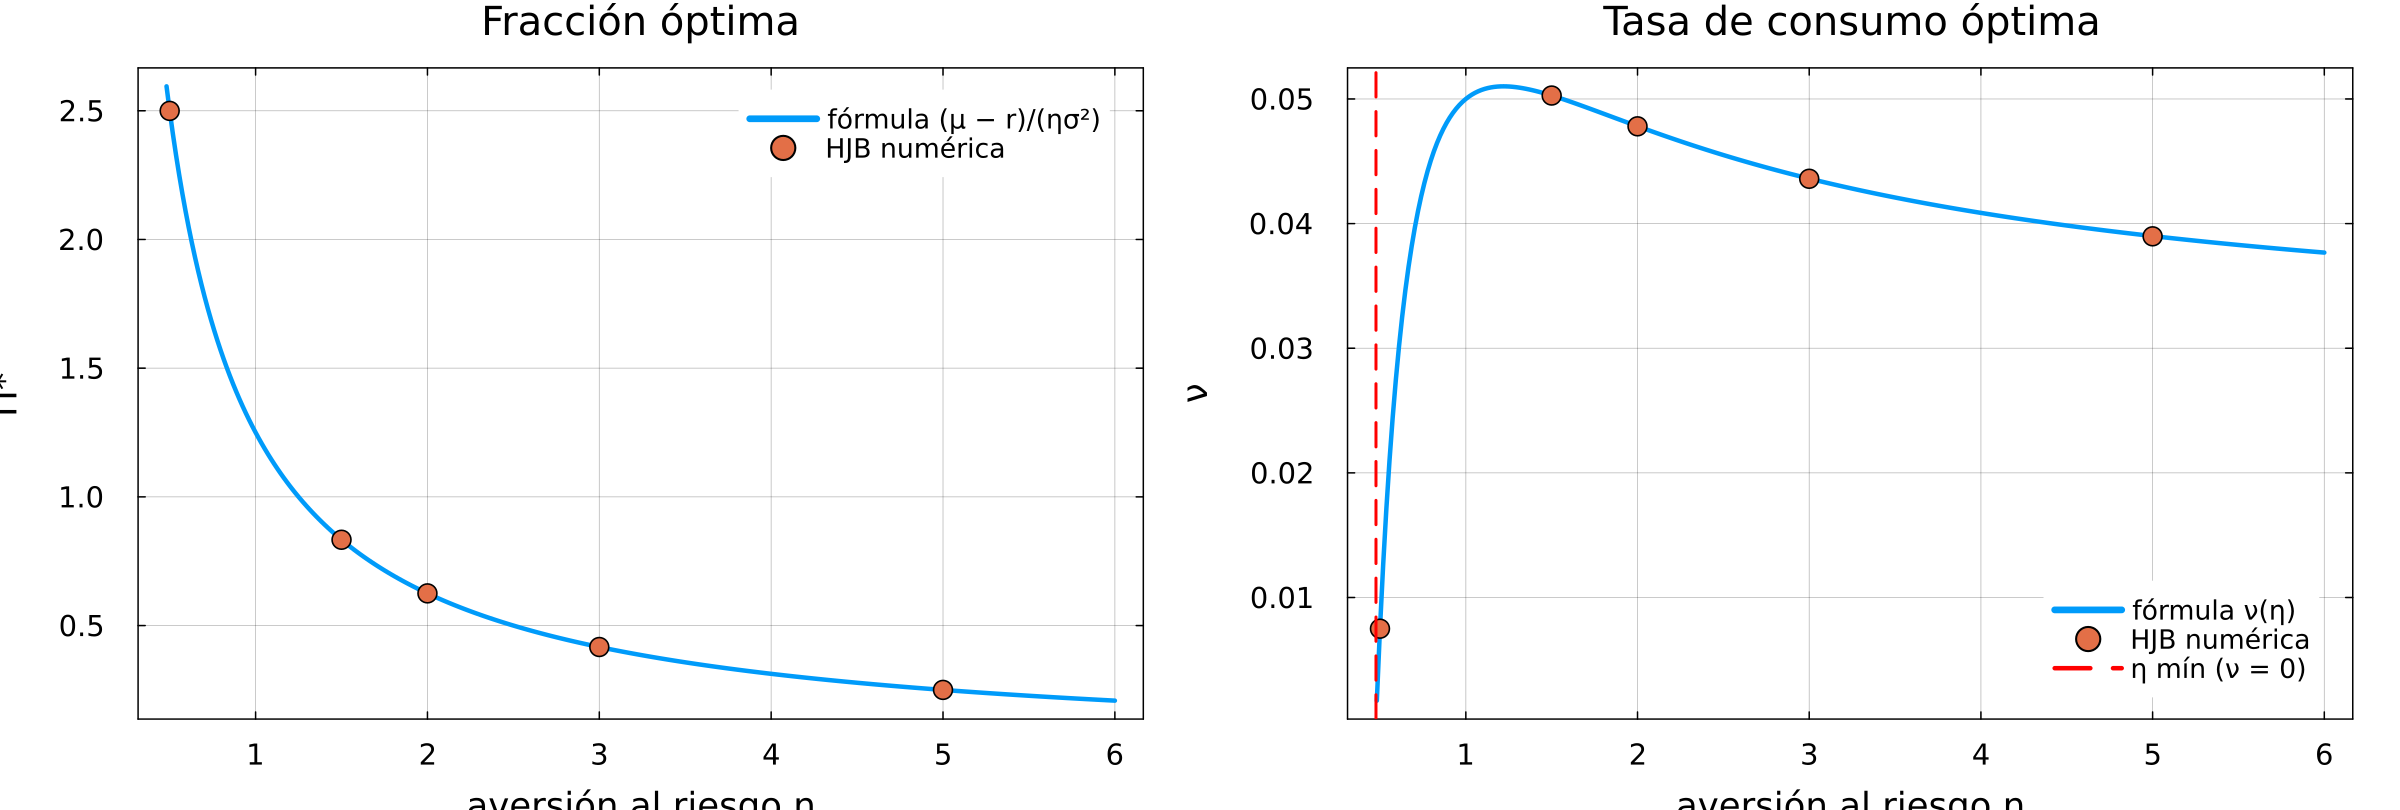

In [16]:
eg = range(eta_min + 0.005, 6, length=300)
q1 = plot(eg, [Pistar(merge(par, (eta = e_,))) for e_ in eg], label="fórmula (μ − r)/(ησ²)",
          xlabel="aversión al riesgo η", ylabel="Π*", title="Fracción óptima")
scatter!(q1, etas, first.(res_eta), label="HJB numérica")
q2 = plot(eg, nu_eta.(eg), label="fórmula ν(η)", xlabel="aversión al riesgo η", ylabel="ν", title="Tasa de consumo óptima",
          legend=:bottomright)
scatter!(q2, etas, last.(res_eta), label="HJB numérica")
vline!(q2, [eta_min], ls=:dash, color=:red, lw=2, label="η mín (ν = 0)")
savefig(plot(q1, dpi=300), "figuras_poster/hjb_fraccion_eta.png")
savefig(plot(q2, dpi=300), "figuras_poster/hjb_consumo_eta.png")
plot(q1, q2, layout=(1, 2), size=(1600, 540))

La sucesión de Howard es creciente, como dice la Proposición 2.2: la política inicial (banco y consumir los intereses) vale lo mismo que tener 65.6 de capital con Merton, tras una mejora se llega a 96.2 y en tres iteraciones a 99.9. El valor límite queda bajo el exacto solo por el error de malla.

Para todos los $\eta>\eta_{\min}\approx0.477$ probados, la HJB numérica coincide con las fórmulas. La fracción óptima cae como $1/\eta$, y la tasa de consumo no es monótona: es máxima cerca de $\eta=1$, y para $\eta<1$ el inversionista consume poco porque prefiere dejar crecer el capital invertido. Cuando $\eta\to\eta_{\min}$, $\nu\to0$: el inversionista posterga el consumo indefinidamente, y para $\eta\le\eta_{\min}$ el valor es infinito y **no existe** control óptimo. La condición $\nu>0$ del teorema de existencia no es solo técnica.

### 2.5 Controles admisibles restringidos (objetivo 6)

#### 2.5.1 Fracción acotada

Ross [R, 2.7] pide $|\Pi_t|\le K_\Pi$, y también es natural prohibir el apalancamiento y la venta corta, $0\le\Pi_t\le1$. Consideramos $\Pi_t\in[\Pi_{\min},\Pi_{\max}]$.

**Proposición 2.3.** Sean $\rho(p)=r+(\mu-r)p-\frac\eta2\sigma^2p^2$ y $\bar p=\mathrm{proy}_{[\Pi_{\min},\Pi_{\max}]}(\Pi^*)$. Si $\nu(\bar p):=\frac{\gamma+(\eta-1)\rho(\bar p)}{\eta}>0$, el control óptimo en la clase restringida es $\Pi_t\equiv\bar p$, $C_t=\nu(\bar p)X_t$, con valor
$$
V_{\bar p}(x)=\frac{1}{1-\eta}\Big(\nu(\bar p)^{-\eta}x^{1-\eta}-\frac1\gamma\Big).
$$
En particular, si $\Pi^*\in[\Pi_{\min},\Pi_{\max}]$ la restricción no cambia nada.

*Demostración.* La Prop. 2.1 sigue valiendo con la restricción, así que $V$ es de la forma $\frac{A}{1-\eta}x^{1-\eta}-\frac{1}{(1-\eta)\gamma}$. Al reemplazar en la HJB, el término que depende de $\Pi$ es $Ax^{1-\eta}\big[\Pi(\mu-r)-\frac\eta2\sigma^2\Pi^2\big]$, una parábola cóncava cuyo máximo sobre el intervalo es la proyección del vértice $\Pi^*$. Con $\Pi=\bar p$, la ecuación para $A$ es la del caso sin restricción con $r+\frac{\theta^2}{2\eta}=\rho(\Pi^*)$ reemplazado por $\rho(\bar p)$, y da $A=\nu(\bar p)^{-\eta}$. La verificación es la misma del reporte. $\blacksquare$

Equivalentemente, $V_{\bar p}(x)=J(x;\bar p,\nu(\bar p))$ con la Prop. 2 del avance 2, y $\nu(\bar p)$ es la tasa de consumo que maximiza $J(x;\bar p,\cdot)$. Comprobamos la proposición con el mismo solver, cambiando solo las cotas de $\Pi$.

In [17]:
rho(p; P=par) = P.r + (P.mu - P.r)*p - 0.5*P.eta*P.sigma^2*p^2
nu_p(p; P=par) = (P.gamma + (P.eta - 1)*rho(p; P=P))/P.eta

y = collect(range(log(1.0), log(1e4), length=801)); i0 = 401
cotas = [("sin restricción",           -5.0, 5.0), ("|Pi| <= 1 (Ross, K = 1)", -1.0, 1.0),
         ("0 <= Pi <= 0.5",             0.0, 0.5), ("0 <= Pi <= 0.25",          0.0, 0.25),
         ("Pi >= 1 (mínimo en acción)", 1.0, 5.0), ("solo banco, Pi = 0",       0.0, 0.0)]
@printf("%-28s %7s %7s %9s %9s %9s %9s %7s\n", "restricción", "Pi HJB", "p", "e HJB", "nu(p)", "W(x0)", "V_p(x0)", "xCE")
for (nombre, lo, hi) in cotas
    s = resolver_hjb(y; Pimin=lo, Pimax=hi)
    p = clamp(Pistar(), lo, hi)
    Vp = Jexacto(p, nu_p(p))
    @printf("%-28s %7.4f %7.4f %9.5f %9.5f %9.4f %9.4f %7.2f\n", nombre, s.Pi[i0], p, s.e[i0], nu_p(p), s.W[i0], Vp, xCE(Vp))
end

restricción                   Pi HJB       p     e HJB     nu(p)     W(x0)   V_p(x0)     xCE
sin restricción               0.6250  0.6250   0.04780   0.04781   15.6226   15.6256  100.00
|Pi| <= 1 (Ross, K = 1)       0.6250  0.6250   0.04780   0.04781   15.6226   15.6256  100.00
0 <= Pi <= 0.5                0.5000  0.5000   0.04749   0.04750   15.5665   15.5679   98.70
0 <= Pi <= 0.25               0.2500  0.2500   0.04499   0.04500   15.0594   15.0617   88.58
Pi >= 1 (mínimo en acción)    1.0000  1.0000   0.04496   0.04500   15.0523   15.0617   88.58
solo banco, Pi = 0            0.0000  0.0000   0.03997   0.04000   13.7410   13.7500   69.99


El solver con cotas reproduce la Proposición 2.3 en todos los casos: la fracción numérica es la proyección de $\Pi^*$, y la tasa de consumo y el valor son los de la fórmula. Tres observaciones:

* Las cotas que contienen a $\Pi^*=0.625$, como $|\Pi|\le1$, no cambian nada: el control de Merton ya era admisible para Ross con cualquier $K_\Pi\ge0.625$, como se dijo en el reporte.
* Con $\eta=2$, $\rho$ es simétrica en torno a $\Pi^*$, así que obligar a $\Pi\ge1$ o a $\Pi\le0.25$ cuesta lo mismo (capital equivalente 88.6): pasarse o quedarse corto por la misma distancia es igual de malo.
* La pérdida es pequeña cerca de $\Pi^*$ ($\Pi\le0.5$ equivale a perder 1.3 de capital) porque $\rho$ es plana en su máximo, y grande lejos de él: no invertir nada equivale a perder 30 de capital.

La restricción también cambia el consumo: con menos rentabilidad, el inversionista con $\eta>1$ consume menos, $\nu(\bar p)<\nu$.

#### 2.5.2 Controles markovianos y no markovianos

Un control es **markoviano** (de retroalimentación) si $\Pi_t=\pi(t,X_t)$ y $C_t=c(t,X_t)$: solo mira el estado actual. Uno **no markoviano** usa la historia, del capital o del precio.

**Proposición 2.4.** Para todo control admisible de $\mathcal A_K$, markoviano o no, $J(x;\Pi,C)\le V(x)$, y el control markoviano de Merton alcanza la igualdad. Por lo tanto, restringir la clase a controles markovianos, o incluso a estrategias proporcionales de fracción constante, **no cambia el valor**.

*Demostración.* La cota por dualidad del reporte (§1.5) usa solo la desigualdad de Fenchel y la restricción presupuestaria, que valen para todo control de $\mathcal A_K$ sin importar cómo dependa de la historia. El control de Merton es markoviano y alcanza la cota. $\blacksquare$

Al revés, restringir a controles **deterministas** en monto ($\Pi_tX_t=\pi(t)$, $C_t=c(t)$) sí es un problema: con ruido el capital es gaussiano y se vuelve negativo con probabilidad positiva, así que esos controles no son admisibles (avance 1, Obs. 4.2).

**Experimento.** Comparamos con Monte-Carlo, en los mismos escenarios, cinco reglas:

| Regla | Tipo |
| --- | --- |
| Merton: $\Pi^*$, $C=\nu X$ | markoviana, óptima |
| Ingenua: $\Pi=1$, $C=0.04X$ | markoviana |
| Caída desde el máximo: $\Pi_t=\Pi^*X_t/\max_{s\le t}X_s$, $C=\nu X$ | no markoviana: baja la exposición tras una caída del capital |
| Media móvil: $\Pi_t=1$ si $S_t$ supera su promedio del último año y $0$ si no, $C=\nu X$ | no markoviana: mira la historia del precio |
| Merton con $\mu$ estimado: $\Pi_t=\frac{\hat\mu_t-r}{\eta\sigma^2}$ (acotada a $[0,2]$), $\hat\mu_t=\frac{\log S_t}{t}+\frac{\sigma^2}2$, desde el año 1 | no markoviana: aprende $\mu$ de los precios (ver la Sección 1) |

Cada regla se aplica hasta $T=30$ años y después se sigue con Merton, así que el estimador es el del avance 2 con valor de continuación $V(X_T)$:
$$
Y=\sum_kw_k\,e^{-\gamma t_k}U(C_{t_k})+e^{-\gamma T}V(X_T),\qquad \mathbb E[Y]\le V(x_0),
$$
porque "la regla hasta $T$ y Merton después" es un control admisible. El capital se simula con el esquema log-Euler congelando el control en cada paso semanal, que es exacto para el control congelado.

In [18]:
# precio de la acción (S_0 = 1) en los mismos escenarios Z; filas = tiempos t_k = (k-1) h
function simular_precio(Z, h; P=par)
    logS = cumsum((P.mu - P.sigma^2/2)*h .+ P.sigma*sqrt(h) .* Z, dims=1)
    return vcat(ones(1, size(Z, 2)), exp.(logS))
end

# Y = utilidad descontada hasta T (trapecio) + e^{-gamma T} V(X_T), para una regla (Pi, e) = regla(k, X, Xmax)
# que se decide al inicio de cada paso con la información disponible y se congela durante el paso
function utilidad_regla(regla, Z, h; P=par)
    K, N = size(Z)
    X = fill(P.x0, N); Xmax = copy(X); Y = zeros(N)
    for k in 1:K
        Pi, e = regla(k, X, Xmax)
        Y .+= (k == 1 ? h/2 : h)*exp(-P.gamma*(k - 1)*h) .* U.(e .* X; P=P)
        X .*= exp.((P.r .+ Pi .* (P.mu - P.r) .- e .- 0.5*P.sigma^2 .* Pi.^2) .* h .+ P.sigma .* Pi .* sqrt(h) .* Z[k, :])
        Xmax .= max.(Xmax, X)
    end
    Pi, e = regla(K + 1, X, Xmax)
    return Y .+ (h/2)*exp(-P.gamma*K*h) .* U.(e .* X; P=P) .+ exp(-P.gamma*K*h) .* V.(X; P=P)
end

utilidad_regla (generic function with 1 method)

In [19]:
Random.seed!(20)
T, h, N = 30.0, 1/52, 5_000
K = round(Int, T/h)
Z = randn(K, N)
S = simular_precio(Z, h)
uno, nuN = ones(N), fill(nustar(), N)

media_movil(k) = Float64.(S[k, :] .> vec(mean(view(S, max(1, k - 52):k, :), dims=1)))
pi_estimado(k) = k <= 53 ? zeros(N) : clamp.((log.(S[k, :]) ./ ((k - 1)*h) .+ par.sigma^2/2 .- par.r) ./ (par.eta*par.sigma^2), 0.0, 2.0)

reglas = ["Merton (markoviana, óptima)"  => (k, X, Xmax) -> (Pistar() .* uno, nuN),
          "Ingenua: Pi = 1, C = 0.04X"   => (k, X, Xmax) -> (uno, 0.04 .* uno),
          "Caída desde el máximo"        => (k, X, Xmax) -> (Pistar() .* X ./ Xmax, nuN),
          "Media móvil de 1 año"         => (k, X, Xmax) -> (media_movil(k), nuN),
          "Merton con mu estimado"       => (k, X, Xmax) -> (pi_estimado(k), nuN)]

res = Dict{String, Vector{Float64}}()
@printf("%-30s %10s %8s %8s\n", "regla", "J_N (MC)", "+-IC95", "xCE")
for (nombre, regla) in reglas
    Y = utilidad_regla(regla, Z, h)
    res[nombre] = Y
    @printf("%-30s %10.4f %8.4f %8.2f\n", nombre, mean(Y), 1.96*std(Y)/sqrt(N), xCE(mean(Y)))
end
@printf("%-30s %10.4f\n\n", "V(x0) exacto", V(par.x0))

YM = res["Merton (markoviana, óptima)"]
@printf("%-30s %12s %10s\n", "regla", "J_M - J", "+-IC95 pareado")
for (nombre, _) in reglas[2:end]
    d = YM .- res[nombre]
    @printf("%-30s %12.4f %10.4f\n", nombre, mean(d), 1.96*std(d)/sqrt(N))
end

regla                            J_N (MC)   +-IC95      xCE
Merton (markoviana, óptima)       15.6225   0.0524    99.93
Ingenua: Pi = 1, C = 0.04X        15.1178   0.1019    89.60
Caída desde el máximo             15.5328   0.0415    97.92
Media móvil de 1 año              14.8063   0.0802    84.22
Merton con mu estimado            14.6525   0.0641    81.80
V(x0) exacto                      15.6256

regla                               J_M - J +-IC95 pareado
Ingenua: Pi = 1, C = 0.04X           0.5047     0.0528
Caída desde el máximo                0.0897     0.0170
Media móvil de 1 año                 0.8163     0.0577
Merton con mu estimado               0.9700     0.0531


Ninguna regla supera a $V(x_0)$ y la de Merton lo alcanza dentro del intervalo de confianza, como dice la Proposición 2.4. Las comparaciones pareadas muestran con significancia que todas las demás son peores:

* **Caída desde el máximo** pierde poco (capital equivalente 97.9): reducir la exposición tras una caída aleja la fracción de $\Pi^*$ justo cuando el capital es bajo. Mirar la historia del capital no ayuda, porque el futuro de la acción no depende de ella.
* **Media móvil** pierde más (84.2): el precio es un movimiento browniano geométrico, sin tendencias que la regla pueda aprovechar, y la regla solo agrega cambios bruscos entre $\Pi=0$ y $\Pi=1$.
* **Merton con $\mu$ estimado** es la peor (81.8): en los primeros años el estimador de $\mu$ es tan ruidoso que la fracción estimada se aleja mucho de $\Pi^*$. Esta regla representa a un inversionista que no conoce $\mu$, y su pérdida es el costo de no conocerlo (Sección 1).

Conclusión: restringirse a controles markovianos no pierde nada. La historia solo sirve cuando hay algo que aprender de ella, como un parámetro desconocido.

### 2.6 Conclusiones y pendientes

**Conclusiones.**
1. La HJB se resuelve numéricamente con un esquema *upwind* monótono e iteración de políticas, con una condición de borde que sale de la homotecia y no necesita conocer $V$. El método converge con orden 1 y reproduce $\Pi^*$, $\nu$ y $V$ (objetivo 5).
2. La iteración de políticas construye controles markovianos admisibles cuyo valor crece hasta $V$, y la condición $\nu>0$ separa los casos con y sin control óptimo: con nuestros parámetros, $\eta>\eta_{\min}\approx0.477$ (objetivo 4).
3. Con la fracción acotada, el óptimo es la proyección de $\Pi^*$ con su propia tasa de consumo $\nu(\bar p)$. Restringir a controles markovianos no pierde valor, y las reglas que miran la historia sin tener nada que aprender son peores (objetivo 6).

**Pendientes.**
* Demostrar la convergencia del esquema a la solución de viscosidad de la HJB (teorema de Barles–Souganidis: monotonía, estabilidad y consistencia); aquí solo la verificamos numéricamente.
* Subir el orden de convergencia sin perder la monotonía, por ejemplo con mallas no uniformes o diferencias centradas donde la difusión domina a la deriva.

El mismo solver se usa en la Sección 3 para un problema sin solución explícita (tiempo de parada con piso).

## 3. Horizonte finito y tiempo de parada (objetivo 7)

Estudiar qué ocurre cuando se acota el tiempo del sistema a un tiempo $T>0$ finito o a un tiempo de parada $\tau$. Incluye la extensión del enunciado "permitir que el sistema se acote a un tiempo finito y que dicho tiempo sea un parámetro modificable".

1. **Horizonte finito $T$** (Secciones 3.1 a 3.3): solución explícita, resolución numérica de la HJB parabólica (que ahora depende del tiempo) y efecto de $T$.
2. **Tiempo de parada aleatorio** $\tau\sim\text{Exp}(\lambda)$, independiente del mercado (Sección 3.4): vida incierta con herencia.
3. **Tiempo de parada que depende del capital** (Sección 3.5): si el capital cae a un piso $x_\ell$, se liquida la inversión y desde ahí solo se usa el banco. Este caso no tiene solución explícita.

El avance 1 (Sección 8) ya resolvió el horizonte finito con el equivalente cierto y OptimalControl.jl; aquí lo hacemos con **programación dinámica**, con el mismo esquema de la Sección 2.

### 3.1 Horizonte finito: solución explícita

Con horizonte $T$ y una **herencia** de peso $\varepsilon\ge0$ (utilidad del capital que queda en $T$), el criterio es
$$
J_T(x;\Pi,C)=\mathbb E_x\Big[\int_0^Te^{-\gamma t}U(C_t)\,dt+\varepsilon\,e^{-\gamma T}U(X_T)\Big],
$$
y la función valor $V(t,x)$ (valor desde el tiempo $t$ con capital $x$) resuelve la HJB **parabólica**
$$
\partial_tV-\gamma V+\sup_{\Pi,\ c\ge0}\Big\{U(c)+\big[(r+\Pi(\mu-r))x-c\big]\partial_xV+\tfrac12\sigma^2\Pi^2x^2\partial_{xx}V\Big\}=0,\qquad V(T,x)=\varepsilon\,U(x).
$$

**Proposición 3.1.** Sean $s=T-t$ el tiempo que falta,
$$
L(s)=\frac1\nu+\Big(\varepsilon^{1/\eta}-\frac1\nu\Big)e^{-\nu s},\qquad D(s)=\frac{1-e^{-\gamma s}}{\gamma}+\varepsilon\,e^{-\gamma s}.
$$
Entonces $V(t,x)=\frac{1}{1-\eta}\big(L(s)^\eta x^{1-\eta}-D(s)\big)$, y el control óptimo es $\Pi^*=\frac{\mu-r}{\eta\sigma^2}$ (el mismo de horizonte infinito) con consumo $C^*_t=X_t/L(T-t)$.

*Demostración.* Probamos $V=\frac{L^\eta x^{1-\eta}}{1-\eta}+g(t)$. Como en el caso estacionario, el supremo en $\Pi$ da $\Pi^*$ y el supremo en $c$ da $c=L^{-1}x$. Agrupando los términos en $x^{1-\eta}$ queda la EDO $L'=\nu L-1$ (con $'=d/dt$), cuya solución con $L(T)=\varepsilon^{1/\eta}$ es la del enunciado; los términos constantes dan $g'-\gamma g=\frac{1}{1-\eta}$ con $g(T)=-\frac{\varepsilon}{1-\eta}$, cuya solución es $g=-\frac{D(s)}{1-\eta}$. La verificación es la del reporte, ahora en $[0,T]$, sin condición de transversalidad. $\blacksquare$

**Consecuencias.**
* La fracción invertida no depende del horizonte: con utilidad CRRA el inversionista no se vuelve más conservador al acercarse a $T$.
* La tasa de consumo $1/L(s)$ sube a medida que se acerca $T$, hasta $\varepsilon^{-1/\eta}$. **Sin herencia** ($\varepsilon=0$) se tiene $L(s)\approx s$ cerca de $T$, así que $C^*/X\approx\frac{1}{T-t}\to\infty$: el inversionista consume todo su capital.
* Cuando $T\to\infty$, $L(s)\to1/\nu$ y $D(s)\to1/\gamma$: se recupera Merton en horizonte infinito.

In [20]:
D(s, eps; P=par) = (1 - exp(-P.gamma*s))/P.gamma + eps*exp(-P.gamma*s)        # s = T - t
L(s, eps; P=par) = 1/nu + (eps^(1/P.eta) - 1/nu)*exp(-nu*s)
VT(s, x, eps; P=par) = (L(s, eps)^P.eta*x^(1 - P.eta) - D(s, eps))/(1 - P.eta)  # valor con s años por delante

for eps in [0.0, 0.1, 1.0]
    @printf("eps = %.1f:  V(0, x0) con T = 20: %.4f   consumo C/X en t = 0: %.4f,  en t = 19: %.4f,  en t = T: %s\n",
            eps, VT(20.0, par.x0, eps), 1/L(20.0, eps), 1/L(1.0, eps), eps > 0 ? @sprintf("%.4f", 1/L(0.0, eps)) : "infinito")
end

eps = 0.0:  V(0, x0) con T = 20: 10.9843   consumo C/X en t = 0: 0.0777,  en t = 19: 1.0241,  en t = T: infinito
eps = 0.1:  V(0, x0) con T = 20: 10.9897   consumo C/X en t = 0: 0.0769,  en t = 19: 0.7825,  en t = T: 3.1623
eps = 1.0:  V(0, x0) con T = 20: 11.2517   consumo C/X en t = 0: 0.0754,  en t = 19: 0.5182,  en t = T: 1.0000


### 3.2 La HJB parabólica numérica

Usamos el esquema de la Sección 2 en $y=\log x$, ahora marchando **hacia atrás en el tiempo** desde $V(T,\cdot)=\varepsilon U$. Con paso $\Delta s$ en $s=T-t$:

* en cada paso calculamos la política $(\Pi,e)$ con las condiciones de primer orden sobre la solución del paso anterior;
* resolvemos el sistema tridiagonal de **Euler implícito**,
$$
\frac{W^{m+1}_i-W^m_i}{\Delta s}=-\gamma W^{m+1}_i+U(e_i\,e^{y_i})+b_i\,(\text{upwind de }W^{m+1})'+a_i\,(W^{m+1})''_i,
$$
que en los nodos interiores sigue siendo una M-matriz (la diagonal gana $1/\Delta s$), así que es estable para cualquier $\Delta s$.

**Proposición 3.2 (homotecia con horizonte finito).** $x\,\partial_xV(t,x)=(1-\eta)V(t,x)+D(T-t)$.

*Demostración.* Igual que la Prop. 2.1: escalar el capital por $\lambda$ multiplica $J_T$ por $\lambda^{1-\eta}$ y le suma $\frac{\lambda^{1-\eta}-1}{1-\eta}D(T-t)$ (la herencia aporta el término $\varepsilon e^{-\gamma s}$). Se deriva en $\lambda=1$. $\blacksquare$

Como en la Sección 2, en los bordes de la malla usamos esta identidad para escribir la ecuación sin vecinos. No usa $L$, solo la función conocida $D$.

La herencia es necesaria para el esquema: con $\varepsilon=0$ el consumo explota en $T$ y la política del primer paso no está definida ($V(T,\cdot)=0$). Por eso resolvemos numéricamente $\varepsilon=1$ y $\varepsilon=0.1$, y el caso $\varepsilon=0$ lo vemos con la fórmula.

In [21]:
# política por condiciones de primer orden; en los bordes, la identidad de homotecia x V_x = (1 - eta) V + Dv
function politica(W, y, Dv; P=par, emax=50.0)
    n = length(W); k = y[2] - y[1]; x = exp.(y)
    W1, W2 = similar(W), similar(W)
    for i in 2:n-1
        W1[i] = (W[i+1] - W[i-1])/(2k); W2[i] = (W[i+1] - 2W[i] + W[i-1])/k^2
    end
    for i in (1, n)
        W1[i] = (1 - P.eta)*W[i] + Dv; W2[i] = (1 - P.eta)*W1[i]
    end
    W1 = max.(W1, 1e-12)
    e = min.((x .^ (1 - P.eta) ./ W1) .^ (1/P.eta), emax)
    den = P.sigma^2 .* (W2 .- W1)
    Pi = [den[i] < 0 ? clamp(-(P.mu - P.r)*W1[i]/den[i], -5.0, 5.0) : 0.0 for i in 1:n]
    return Pi, e
end

# HJB parabólica hacia atrás desde t = T, con M pasos de Euler implícito.
# Devuelve W(0, .), la política en t = 0 y la tasa de consumo en x0 a lo largo del tiempo.
function resolver_finito(y, T, M; eps=1.0, P=par)
    n = length(y); k = y[2] - y[1]; x = exp.(y); ds = T/M
    i0 = argmin(abs.(x .- P.x0))
    W = eps .* U.(x; P=P)                               # condición final V(T, x) = eps U(x)
    e_x0 = zeros(M)
    for m in 1:M
        Pi, e = politica(W, y, D((m - 1)*ds, eps; P=P); P=P)
        e_x0[m] = e[i0]
        b = P.r .+ Pi .* (P.mu - P.r) .- e .- 0.5*P.sigma^2 .* Pi.^2
        a = 0.5*P.sigma^2 .* Pi.^2
        bp, bm = max.(b, 0), max.(-b, 0)
        dl = -(bm ./ k .+ a ./ k^2)
        d  = 1/ds .+ P.gamma .+ (bp .+ bm) ./ k .+ 2a ./ k^2
        du = -(bp ./ k .+ a ./ k^2)
        rhs = U.(e .* x; P=P) .+ W ./ ds
        for i in (1, n)                                 # bordes: Prop. 3.2
            dl[i] = 0.0; du[i] = 0.0
            d[i] = 1/ds + kappa(Pi[i], e[i]; P=P)
            rhs[i] = W[i]/ds + U(e[i]*x[i]; P=P) + (b[i] + (1 - P.eta)*a[i])*D(m*ds, eps; P=P)
        end
        W = Tridiagonal(dl[2:n], d, du[1:n-1]) \ rhs
    end
    Pi, e = politica(W, y, D(T, eps; P=P); P=P)
    return (W=W, Pi=Pi, e=e, x=x, s=ds .* (0:M-1), e_x0=e_x0)
end

resolver_finito (generic function with 1 method)

In [22]:
T = 20.0
println("  eps     n     M   W(0,x0)    exacto     error   Pi(0,x0)   C/X en t=0   exacto")
for eps in [1.0, 0.1], (n, M) in [(201, 200), (401, 400), (801, 800), (1601, 1600)]
    y = collect(range(log(1.0), log(1e4), length=n)); i0 = (n + 1) ÷ 2
    s = resolver_finito(y, T, M; eps=eps)
    @printf("%5.1f %5d %5d %9.4f %9.4f %9.1e %9.4f %11.5f %9.5f\n", eps, n, M, s.W[i0], VT(T, par.x0, eps),
            s.W[i0] - VT(T, par.x0, eps), s.Pi[i0], s.e[i0], 1/L(T, eps))
end

  eps     n     M   W(0,x0)    exacto     error   Pi(0,x0)   C/X en t=0   exacto
  1.0   201   200   11.2049   11.2517  -4.7e-02    0.6251     0.07477   0.07541
  1.0   401   400   11.2286   11.2517  -2.3e-02    0.6250     0.07510   0.07541
  1.0   801   800   11.2402   11.2517  -1.1e-02    0.6250     0.07526   0.07541
  1.0  1601  1600   11.2460   11.2517  -5.7e-03    0.6250     0.07533   0.07541
  0.1   201   200   10.9345   10.9897  -5.5e-02    0.6251     0.07610   0.07693
  0.1   401   400   10.9627   10.9897  -2.7e-02    0.6250     0.07653   0.07693
  0.1   801   800   10.9763   10.9897  -1.3e-02    0.6250     0.07673   0.07693
  0.1  1601  1600   10.9830   10.9897  -6.6e-03    0.6250     0.07683   0.07693


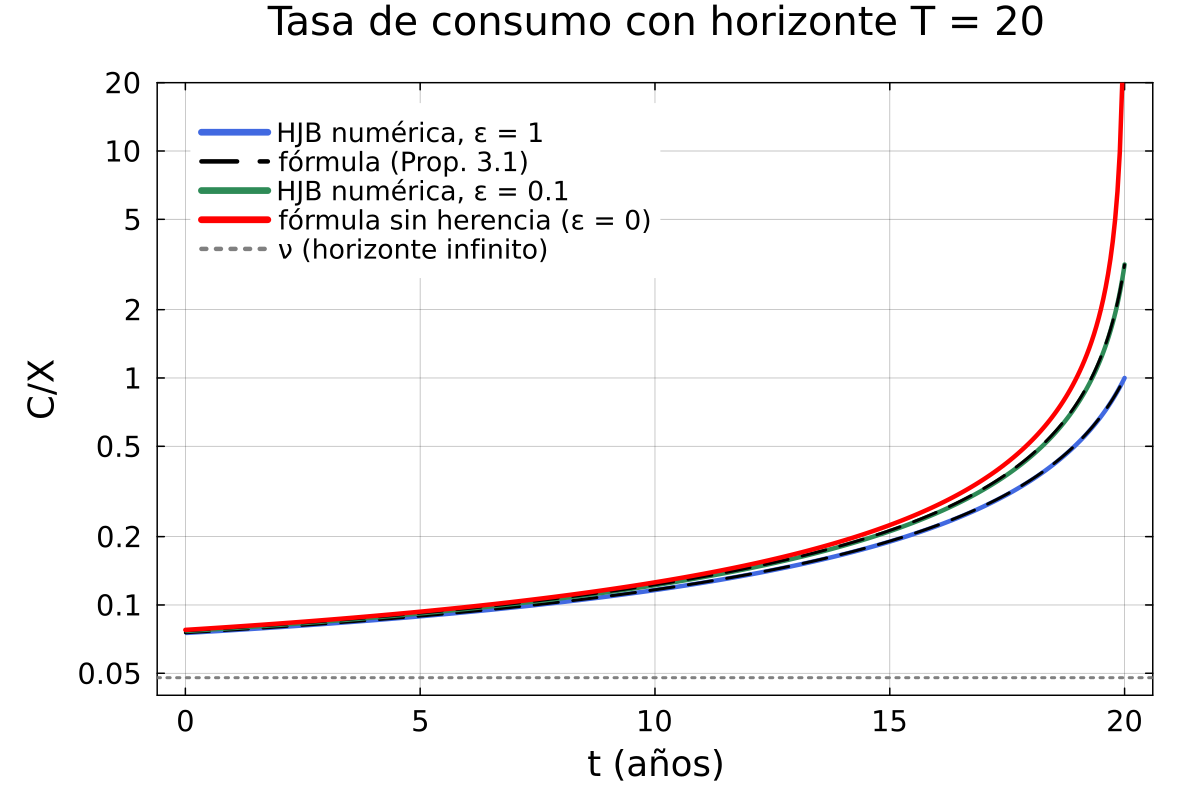

In [23]:
y = collect(range(log(1.0), log(1e4), length=801))
tt = range(0, T - 1e-3, length=400)
pe = plot(xlabel="t (años)", ylabel="C/X", title="Tasa de consumo con horizonte T = 20", yscale=:log10,
          ylims=(0.04, 20), legend=:topleft,
          yticks=([0.05, 0.1, 0.2, 0.5, 1, 2, 5, 10, 20], ["0.05", "0.1", "0.2", "0.5", "1", "2", "5", "10", "20"]))
for (eps, col, txt) in [(1.0, :royalblue, "1"), (0.1, :seagreen, "0.1")]
    s = resolver_finito(y, T, 800; eps=eps)
    plot!(pe, T .- s.s, s.e_x0, color=col, label="HJB numérica, ε = $txt")
    plot!(pe, tt, 1 ./ L.(T .- tt, eps), color=:black, ls=:dash, lw=2, label=(eps == 1.0 ? "fórmula (Prop. 3.1)" : false))
end
plot!(pe, tt, 1 ./ L.(T .- tt, 0.0), color=:red, label="fórmula sin herencia (ε = 0)")
hline!(pe, [nu], color=:gray, ls=:dot, lw=2, label="ν (horizonte infinito)")
savefig(plot(pe, dpi=300), "figuras_poster/horizonte_consumo.png")
pe

El esquema converge con orden 1 a la solución de la Proposición 3.1 (el error en $V(0,x_0)$ se divide por dos al duplicar $n$ y $M$), y la fracción numérica en $t=0$ es $\Pi^*=0.625$. En el gráfico, la tasa de consumo numérica sigue a la fórmula $1/L(T-t)$: sube lentamente durante casi todo el horizonte y se dispara en los últimos años, hasta $\varepsilon^{-1/\eta}$ en $t=T$ (1 con $\varepsilon=1$ y 3.16 con $\varepsilon=0.1$). Sin herencia, la fórmula explota como $1/(T-t)$: el inversionista se consume todo el capital antes de $T$. Incluso al inicio se consume más que en horizonte infinito (0.075 frente a $\nu=0.048$), porque hay menos años entre los que repartir el capital.

### 3.3 El horizonte como parámetro

¿Cuánto importa $T$? Con la Proposición 3.1 calculamos el valor $V(0,x_0)$ y la tasa de consumo inicial para $T$ entre 1 y 100 años, con y sin herencia, y los comparamos con el horizonte infinito. Agregamos puntos de la HJB numérica para $\varepsilon=1$.

T =  10: V(0,x0) sin herencia =   7.2375, con herencia =   7.7417  (infinito: 15.6256);  C/X inicial = 0.1258 / 0.1167  (nu = 0.0478)
T =  30: V(0,x0) sin herencia =  12.9992, con herencia =  13.1458  (infinito: 15.6256);  C/X inicial = 0.0628 / 0.0618  (nu = 0.0478)
T =  60: V(0,x0) sin herencia =  15.1124, con herencia =  15.1398  (infinito: 15.6256);  C/X inicial = 0.0507 / 0.0505  (nu = 0.0478)
T = 100: V(0,x0) sin herencia =  15.5639, con herencia =  15.5672  (infinito: 15.6256);  C/X inicial = 0.0482 / 0.0482  (nu = 0.0478)


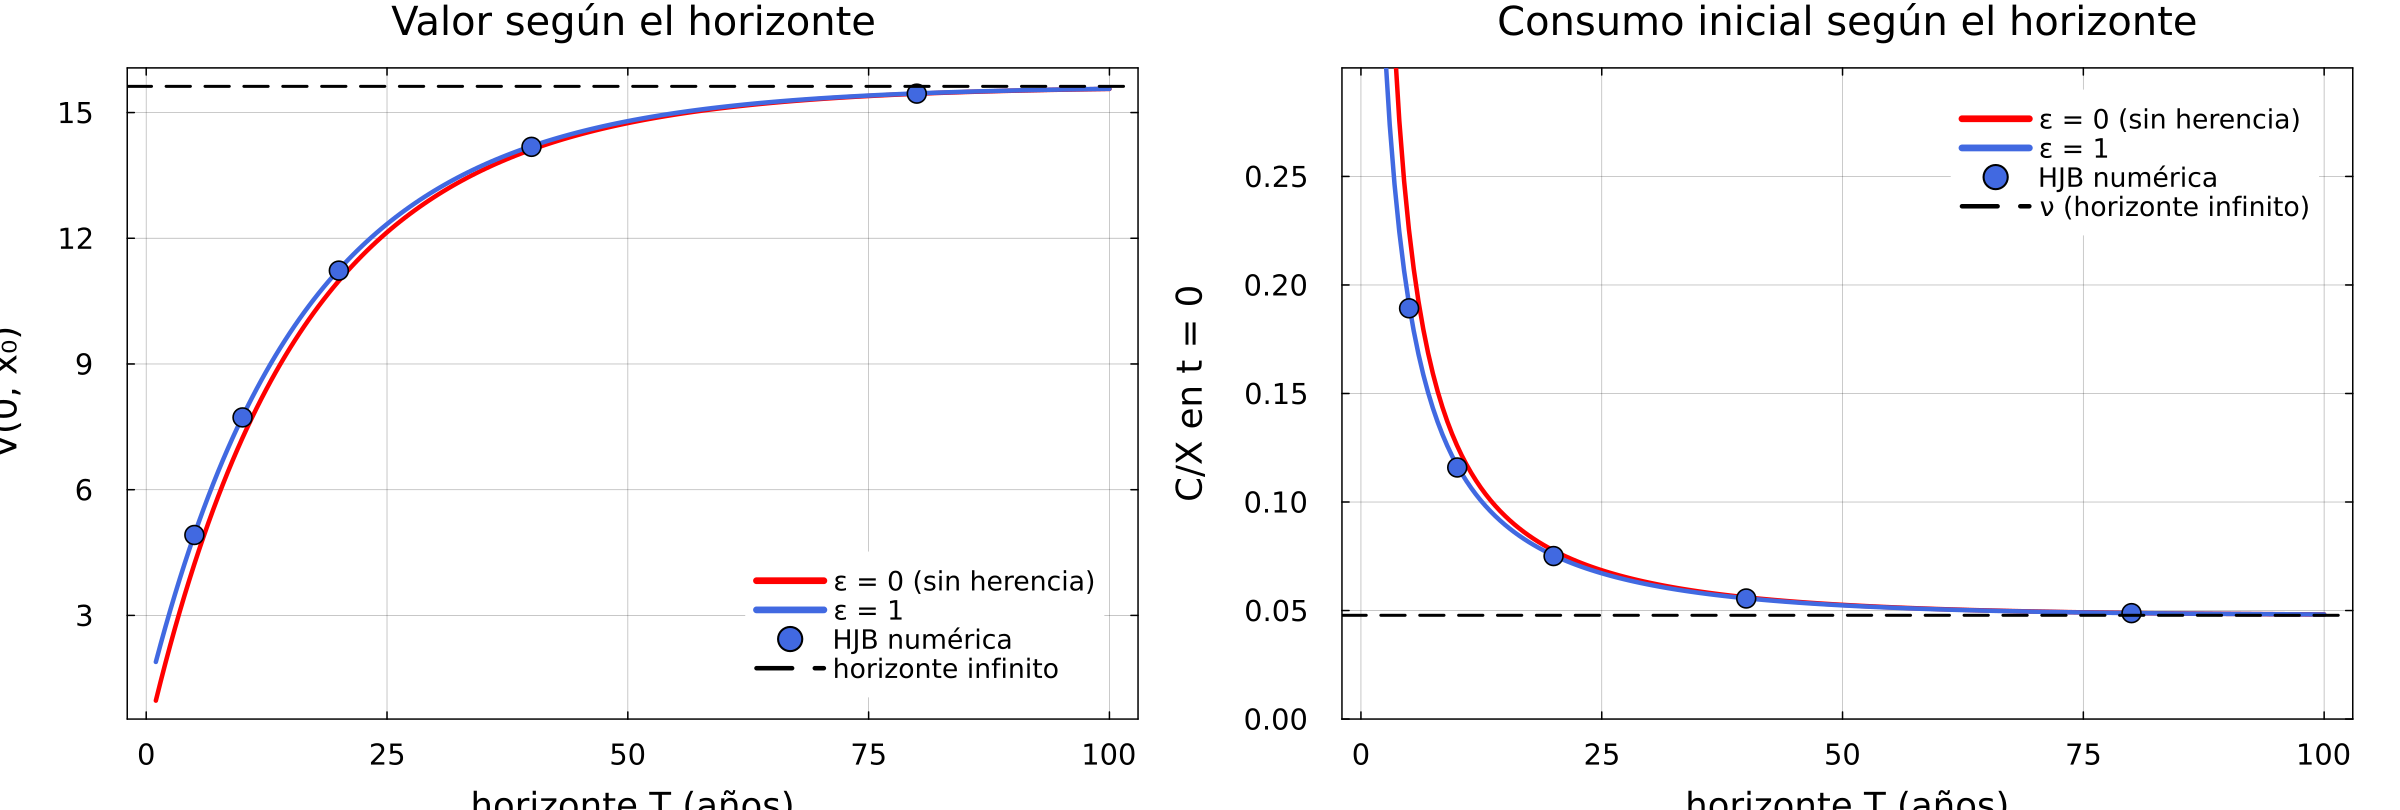

In [24]:
Ts = range(1, 100, length=200)
pv = plot(xlabel="horizonte T (años)", ylabel="V(0, x₀)", title="Valor según el horizonte", legend=:bottomright)
pc = plot(xlabel="horizonte T (años)", ylabel="C/X en t = 0", title="Consumo inicial según el horizonte", legend=:topright,
          ylims=(0, 0.3))
for (eps, col, txt) in [(0.0, :red, "ε = 0 (sin herencia)"), (1.0, :royalblue, "ε = 1")]
    plot!(pv, Ts, VT.(Ts, par.x0, eps), color=col, label=txt)
    plot!(pc, Ts, 1 ./ L.(Ts, eps), color=col, label=txt)
end
Tnum = [5.0, 10.0, 20.0, 40.0, 80.0]
Wnum = [resolver_finito(collect(range(log(1.0), log(1e4), length=401)), Tn, round(Int, 20Tn); eps=1.0) for Tn in Tnum]
scatter!(pv, Tnum, [w.W[201] for w in Wnum], color=:royalblue, label="HJB numérica")
scatter!(pc, Tnum, [w.e[201] for w in Wnum], color=:royalblue, label="HJB numérica")
hline!(pv, [V(par.x0)], color=:black, ls=:dash, lw=2, label="horizonte infinito")
hline!(pc, [nu], color=:black, ls=:dash, lw=2, label="ν (horizonte infinito)")
for Tn in [10, 30, 60, 100]
    @printf("T = %3d: V(0,x0) sin herencia = %8.4f, con herencia = %8.4f  (infinito: %.4f);  C/X inicial = %.4f / %.4f  (nu = %.4f)\n",
            Tn, VT(Tn, par.x0, 0.0), VT(Tn, par.x0, 1.0), V(par.x0), 1/L(Tn, 0.0), 1/L(Tn, 1.0), nu)
end
savefig(plot(pv, dpi=300), "figuras_poster/horizonte_valor.png")
savefig(plot(pc, dpi=300), "figuras_poster/horizonte_consumo_inicial.png")
plot(pv, pc, layout=(1, 2), size=(1600, 540))

El horizonte importa mucho, y por mucho tiempo: con $T=10$ el valor es 7.7, lejos del 15.6 de horizonte infinito, y con $T=60$ todavía hay una diferencia de 0.5. La razón es que $L(s)$ se acerca a $1/\nu$ como $e^{-\nu s}$, con $1/\nu\approx21$ años: hacen falta unos $3/\nu\approx60$ años para que el horizonte deje de importar, y lo mismo pasa con la tasa de consumo inicial. La herencia aumenta el valor y baja el consumo inicial, pero su efecto desaparece en horizontes largos porque está descontada por $e^{-\gamma T}$. La HJB numérica coincide con la fórmula en todos los horizontes probados.

### 3.4 Tiempo de parada aleatorio: vida incierta

Ahora el sistema se detiene en un tiempo aleatorio $\tau\sim\text{Exp}(\lambda)$ independiente del browniano (por ejemplo, la muerte del inversionista, con esperanza $1/\lambda$ años), y en $\tau$ se deja una herencia $\varepsilon\,U(X_\tau)$:
$$
J=\mathbb E_x\Big[\int_0^\tau e^{-\gamma t}U(C_t)\,dt+\varepsilon\,e^{-\gamma\tau}U(X_\tau)\Big].
$$

**Proposición 3.3.** $J=\mathbb E_x\int_0^\infty e^{-(\gamma+\lambda)t}\big[U(C_t)+\lambda\varepsilon\,U(X_t)\big]dt$: es un problema de horizonte infinito con descuento $\gamma+\lambda$. Su solución es $\Pi^*=\frac{\mu-r}{\eta\sigma^2}$ (sin cambios), $C^*=X/L_\lambda$ y
$$
V(x)=\frac{L_\lambda^\eta x^{1-\eta}}{1-\eta}-\frac{1+\lambda\varepsilon}{(1-\eta)(\gamma+\lambda)},
$$
donde $L_\lambda>0$ resuelve $\eta\nu_\lambda L^\eta-\eta L^{\eta-1}-\lambda\varepsilon=0$ con $\nu_\lambda=\nu+\frac\lambda\eta$. Sin herencia, $L_\lambda=1/\nu_\lambda$.

*Demostración.* Por independencia y Fubini, $\mathbb E\int_0^\tau f(t)dt=\int_0^\infty\mathbb P(\tau>t)f(t)dt=\int_0^\infty e^{-\lambda t}f(t)dt$ y $\mathbb E[e^{-\gamma\tau}U(X_\tau)]=\int_0^\infty\lambda e^{-\lambda t}e^{-\gamma t}\mathbb E[U(X_t)]dt$, lo que da la primera fórmula. La HJB es la de Merton con $\gamma+\lambda$ en lugar de $\gamma$ y el término extra $\lambda\varepsilon U(x)$; con el ansatz $V=\frac{A}{1-\eta}x^{1-\eta}+K$ y $A=L^\eta$, el término en $\Pi$ no cambia, y los coeficientes de $x^{1-\eta}$ y de la constante dan las dos ecuaciones del enunciado. $\blacksquare$

**Interpretación.** El riesgo de morir hace al inversionista más **impaciente**: consume más ($\nu_\lambda>\nu$), y la herencia modera ese efecto. La fracción invertida no cambia.

Lo validamos simulando directamente el tiempo de parada: en cada trayectoria se sortea $\tau$, se simula el capital con el esquema exacto hasta $\tau$ y se suma la utilidad realizada.

In [25]:
# L_lambda de la Prop. 3.3 por bisección
function L_exp(lam, eps; P=par)
    nul = nu + lam/P.eta
    f(Lv) = P.eta*nul*Lv^P.eta - P.eta*Lv^(P.eta - 1) - lam*eps
    a, b = 1e-6, 1e4
    for _ in 1:200
        m = (a + b)/2
        f(m) > 0 ? (b = m) : (a = m)
    end
    return (a + b)/2
end
V_exp(x, lam, eps; P=par) = L_exp(lam, eps)^P.eta*x^(1 - P.eta)/(1 - P.eta) - (1 + lam*eps)/((1 - P.eta)*(P.gamma + lam))

# Monte-Carlo con tau ~ Exp(lam): utilidad hasta tau (trapecio, y el último tramo parcial) + herencia en tau
function mc_exponencial(lam, eps; N=20_000, h=1/52, semilla=1, P=par)
    rng = Xoshiro(semilla)
    Lx = L_exp(lam, eps)
    a = P.r + Pim*(P.mu - P.r) - 1/Lx - 0.5*P.sigma^2*Pim^2     # deriva de log X con (Pi*, X/L)
    Y = zeros(N)
    for i in 1:N
        tau = randexp(rng)/lam
        lx, t, acc = log(P.x0), 0.0, 0.0
        while t + h <= tau
            f0 = exp(-P.gamma*t)*U(exp(lx)/Lx)
            lx += a*h + P.sigma*Pim*sqrt(h)*randn(rng)
            acc += h/2*(f0 + exp(-P.gamma*(t + h))*U(exp(lx)/Lx)); t += h
        end
        resto = tau - t                                          # tramo final [t, tau)
        acc += resto*exp(-P.gamma*t)*U(exp(lx)/Lx)
        lx += a*resto + P.sigma*Pim*sqrt(resto)*randn(rng)
        Y[i] = acc + eps*exp(-P.gamma*tau)*U(exp(lx))
    end
    return mean(Y), 1.96*std(Y)/sqrt(N)
end

println("vida esperada  herencia   C/X = 1/L    V exacto   Monte-Carlo +- IC95   (50 000 trayectorias)")
for (j, (lam, eps)) in enumerate([(l, e) for l in [1/50, 1/30, 1/10] for e in [0.0, 1.0, 5.0]])
    m, s = mc_exponencial(lam, eps; N=50_000, semilla=j)
    @printf("%8.0f años %8.1f %11.5f %11.4f %11.4f +- %.4f\n", 1/lam, eps, 1/L_exp(lam, eps), V_exp(par.x0, lam, eps), m, s)
end
@printf("(sin riesgo de muerte: C/X = nu = %.5f, V(x0) = %.4f)\n", nu, V(par.x0))

vida esperada  herencia   C/X = 1/L    V exacto   Monte-Carlo +- IC95   (50 000 trayectorias)
      50 años      0.0     0.05781     11.2937     11.2943 +- 0.0412
      50 años      1.0     0.05778     11.5760     11.5418 +- 0.0389
      50 años      5.0     0.05765     12.7050     12.7075 +- 0.0294
      30 años      0.0     0.06448      9.5947      9.6176 +- 0.0419
      30 años      1.0     0.06441      9.9896      9.9950 +- 0.0393
      30 años      5.0     0.06414     11.5690     11.5485 +- 0.0296
      10 años      0.0     0.09781      5.6214      5.6051 +- 0.0332
      10 años      1.0     0.09734      6.2779      6.2611 +- 0.0312
      10 años      5.0     0.09553      8.9042      8.9007 +- 0.0232
(sin riesgo de muerte: C/X = nu = 0.04781, V(x0) = 15.6256)


Los nueve casos coinciden con la Proposición 3.3 dentro del intervalo de confianza. La vida incierta cambia mucho el consumo: con una vida esperada de 30 años la tasa sube de $\nu=0.048$ a 0.064, y con 10 años a casi 0.098. La herencia baja el consumo solo un poco (de 0.098 a 0.096 con $\varepsilon=5$ y 10 años), porque se recibe en un momento aleatorio y descontado. La fracción invertida es siempre $\Pi^*=0.625$: el riesgo de morir no hace al inversionista más conservador, solo más impaciente.

### 3.5 Tiempo de parada que depende del capital: piso de liquidación

Supongamos que si el capital cae a un piso $x_\ell<x_0$ el inversionista es obligado a liquidar la acción (por ejemplo, por una regla de riesgo), y desde ese momento solo puede usar el banco: $\tau=\inf\{t:X_t\le x_\ell\}$. Después de $\tau$ obtiene el valor del problema "solo banco", que por la Prop. 2.3 con $\bar p=0$ es
$$
\Psi(x)=\frac{1}{1-\eta}\Big(\nu(0)^{-\eta}x^{1-\eta}-\frac1\gamma\Big),\qquad \nu(0)=\frac{\gamma+(\eta-1)r}{\eta}.
$$
El problema es $V_\ell(x)=\sup\mathbb E_x\big[\int_0^\tau e^{-\gamma t}U(C_t)dt+e^{-\gamma\tau}\Psi(X_\tau)\big]$, y su HJB es la misma de siempre en $x>x_\ell$, con la condición de borde $V_\ell(x_\ell)=\Psi(x_\ell)$.

**El piso rompe la homotecia:** al escalar el capital se escala también la distancia al piso, así que $V_\ell$ ya no es de la forma $Ax^{1-\eta}+K$, y el control óptimo deja de ser constante. No hay solución explícita, así que usamos el solver de la Sección 2 con la condición de Dirichlet en $x_\ell$. Lejos del piso el problema se parece al de Merton, y en el borde derecho seguimos usando la homotecia como aproximación. Siempre se cumple $\Psi\le V_\ell\le V$: el inversionista puede elegir el banco desde el inicio, y sin piso estaría mejor.

In [26]:
nu0 = (par.gamma + (par.eta - 1)*par.r)/par.eta
Psi(x; P=par) = (nu0^(-P.eta)*x^(1 - P.eta) - 1/P.gamma)/(1 - P.eta)   # valor de "solo banco"

# HJB estacionaria en [log xl, log xmax] con Dirichlet V(xl) = Psi(xl) y homotecia en el borde derecho
function resolver_piso(y; P=par, tol=1e-10, maxit=200)
    n = length(y); k = y[2] - y[1]; x = exp.(y)
    Pi = fill(0.0, n); e = fill(P.r, n); W = zeros(n)
    for it in 1:maxit
        b = P.r .+ Pi .* (P.mu - P.r) .- e .- 0.5*P.sigma^2 .* Pi.^2
        a = 0.5*P.sigma^2 .* Pi.^2
        bp, bm = max.(b, 0), max.(-b, 0)
        dl = -(bm ./ k .+ a ./ k^2); d = P.gamma .+ (bp .+ bm) ./ k .+ 2a ./ k^2; du = -(bp ./ k .+ a ./ k^2)
        rhs = U.(e .* x; P=P)
        dl[1] = 0.0; du[1] = 0.0; d[1] = 1.0; rhs[1] = Psi(x[1])          # piso: liquidación
        dl[n] = 0.0; du[n] = 0.0; d[n] = kappa(Pi[n], e[n])                # borde derecho: homotecia
        rhs[n] = U(e[n]*x[n]) + (b[n] + (1 - P.eta)*a[n])/P.gamma
        Wn = Tridiagonal(dl[2:n], d, du[1:n-1]) \ rhs
        Pi, e = politica(Wn, y, 1/P.gamma)
        cambio = maximum(abs.(Wn .- W))/maximum(abs.(Wn)); W = Wn
        cambio < tol && break
    end
    return (W=W, Pi=Pi, e=e, x=x, y=y)
end

pisos = [20.0, 50.0, 80.0]; sols = Dict()
@printf("%8s %10s %8s %9s %10s   (Merton: V = %.4f, Pi* = %.3f, nu = %.4f; solo banco: %.4f)\n", "piso", "V_l(x0)", "xCE",
        "Pi(x0)", "C/X(x0)", V(par.x0), Pim, nu, Psi(par.x0))
for xl in pisos
    s = resolver_piso(collect(range(log(xl), log(1e4), length=801)))
    sols[xl] = s
    i0 = argmin(abs.(s.x .- par.x0))
    xce = (nu^par.eta*((1 - par.eta)*s.W[i0] + 1/par.gamma))^(1/(1 - par.eta))
    @printf("%8.0f %10.4f %8.2f %9.4f %10.4f\n", xl, s.W[i0], xce, s.Pi[i0], s.e[i0])
end

    piso    V_l(x0)      xCE    Pi(x0)    C/X(x0)   (Merton: V = 15.6256, Pi* = 0.625, nu = 0.0478; solo banco: 13.7500)
      20    15.5781    98.92    0.6095     0.0472
      50    15.3879    94.85    0.5313     0.0440
      80    14.8625    85.15    0.3556     0.0370


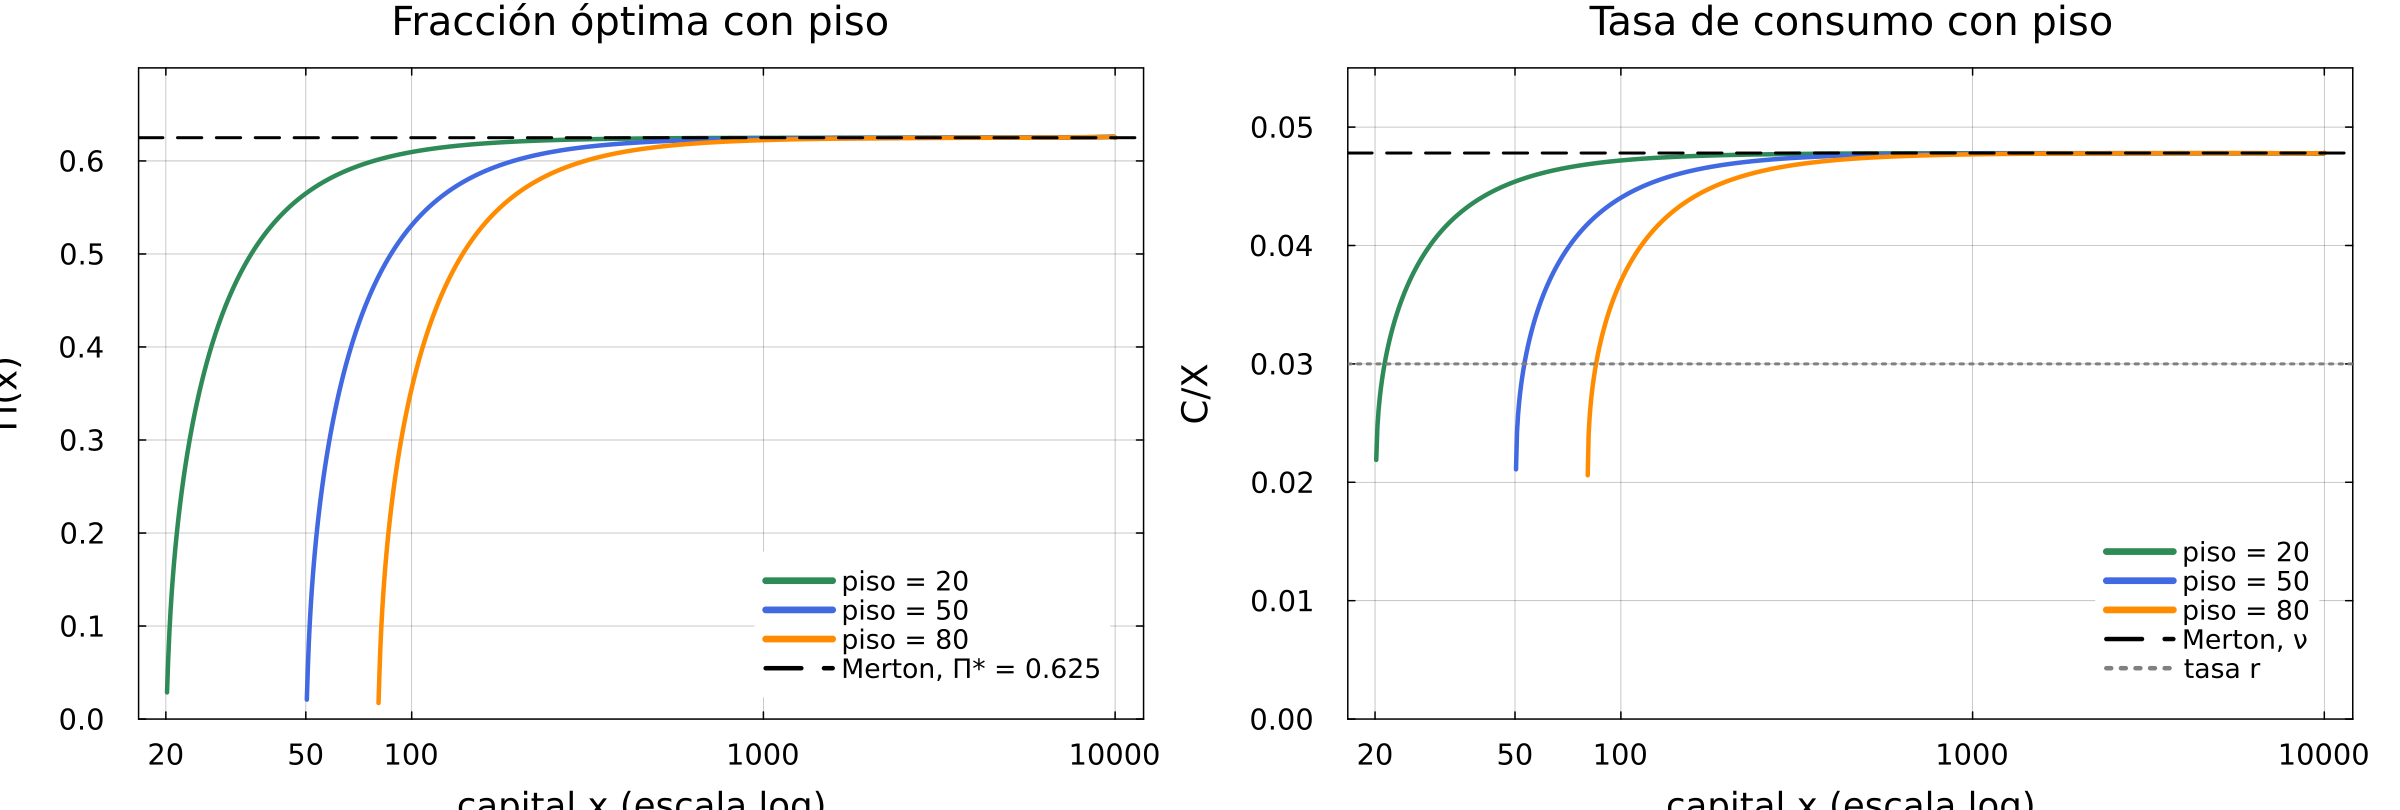

In [27]:
ejex = ([20, 50, 100, 1000, 10000], ["20", "50", "100", "1000", "10000"])   # marcas del eje x en escala log
q1 = plot(xlabel="capital x (escala log)", ylabel="Π(x)", title="Fracción óptima con piso", xscale=:log10,
          legend=:bottomright, ylims=(0, 0.7), xticks=ejex)
q2 = plot(xlabel="capital x (escala log)", ylabel="C/X", title="Tasa de consumo con piso", xscale=:log10,
          legend=:bottomright, ylims=(0, 0.055), xticks=ejex)
for (xl, col) in zip(pisos, [:seagreen, :royalblue, :darkorange])
    s = sols[xl]
    plot!(q1, s.x[2:end], s.Pi[2:end], color=col, label="piso = $(Int(xl))")
    plot!(q2, s.x[2:end], s.e[2:end], color=col, label="piso = $(Int(xl))")
end
hline!(q1, [Pim], color=:black, ls=:dash, lw=2, label="Merton, Π* = 0.625")
hline!(q2, [nu], color=:black, ls=:dash, lw=2, label="Merton, ν")
hline!(q2, [par.r], color=:gray, ls=:dot, lw=2, label="tasa r")
savefig(plot(q1, dpi=300), "figuras_poster/piso_fraccion.png")
savefig(plot(q2, dpi=300), "figuras_poster/piso_consumo.png")
plot(q1, q2, layout=(1, 2), size=(1600, 540))

El piso cambia el control: lejos del piso el inversionista actúa como Merton, pero al acercarse **reduce la fracción invertida casi a cero** y **consume menos que la tasa de interés** $r$. Así, cerca del piso el capital crece en forma casi determinista y se aleja de la liquidación: conviene sacrificar rentabilidad antes que perder la posibilidad de invertir. Cuanto más alto el piso, más se nota desde $x_0$: con $x_\ell=80$, en $x_0=100$ invierte solo 0.36 y su valor equivale a tener 85 de capital sin piso. Con $x_\ell=20$ el piso casi no importa ($x_{CE}=98.9$).

**Verificación por simulación.** Simulamos el capital con el control numérico (interpolado entre nodos) para $x_\ell=50$, detenemos cada trayectoria si toca el piso (y sumamos $e^{-\gamma\tau}\Psi(X_\tau)$), y a las que no lo tocan en 100 años les sumamos el valor numérico $e^{-\gamma T}V_\ell(X_T)$. Si la solución numérica es correcta, el promedio debe reproducir $V_\ell(x_0)$ (identidad de martingala, como en el avance 2).

In [28]:
# interpolación lineal en la malla uniforme y
interp_y(yq, y, v) = (k = y[2] - y[1]; j = clamp(floor(Int, (yq - y[1])/k) + 1, 1, length(y) - 1);
                    a = (yq - y[j])/k; (1 - a)*v[j] + a*v[j+1])

function mc_piso(s, xl; N=5_000, h=1/52, Tsim=100.0, semilla=8, P=par)
    rng = Xoshiro(semilla); K = round(Int, Tsim/h)
    Y = zeros(N); tocan = 0
    for i in 1:N
        x, acc, parado = P.x0, 0.0, false
        f0 = U(interp_y(log(x), s.y, s.e)*x)
        for k in 1:K
            ly = log(x); Pi = interp_y(ly, s.y, s.Pi); e = interp_y(ly, s.y, s.e)
            x *= exp((P.r + Pi*(P.mu - P.r) - e - 0.5*P.sigma^2*Pi^2)*h + P.sigma*Pi*sqrt(h)*randn(rng))
            if x <= xl                                           # se toca el piso: liquidación
                acc += h/2*f0 + exp(-P.gamma*k*h)*Psi(x); parado = true; tocan += 1
                break
            end
            f1 = exp(-P.gamma*k*h)*U(interp_y(log(x), s.y, s.e)*x)
            acc += h/2*(f0 + f1); f0 = f1
        end
        parado || (acc += exp(-P.gamma*K*h)*interp_y(log(x), s.y, s.W))
        Y[i] = acc
    end
    return mean(Y), 1.96*std(Y)/sqrt(N), tocan/N
end

s50 = sols[50.0]; i0 = argmin(abs.(s50.x .- par.x0))
m, ic, frac = mc_piso(s50, 50.0)
@printf("piso 50: Monte-Carlo = %.4f +- %.4f   vs   V_l(x0) numérico = %.4f;   fracción que toca el piso: %.4f\n", m, ic, s50.W[i0], frac)

piso 50: Monte-Carlo = 15.3797 +- 0.0483   vs   V_l(x0) numérico = 15.3879;   fracción que toca el piso: 0.0382


La simulación reproduce el valor numérico dentro del intervalo de confianza, así que la solución de la HJB con piso es consistente. Además, solo el 3.8% de las trayectorias toca el piso en 100 años: el control óptimo casi elimina la liquidación, como se veía en los gráficos.

In [29]:
# figura del reporte: tres paneles en una fila con letras más chicas
fig = plot(pe, pv, q1, layout=(1, 3), size=(1200, 340), titlefontsize=10, guidefontsize=9, tickfontsize=8,
           legendfontsize=6, bottom_margin=6Plots.mm, left_margin=5Plots.mm)
mkpath("figuras_final"); savefig(fig, "figuras_final/horizonte_parada.pdf");

### 3.6 Conclusiones y pendientes

**Conclusiones.**
1. Con horizonte finito el control óptimo sigue siendo $\Pi^*$ constante, pero la tasa de consumo $1/L(T-t)$ crece hacia $T$, y sin herencia explota como $1/(T-t)$. La HJB parabólica numérica converge a la solución explícita con orden 1.
2. El horizonte es un parámetro relevante: el problema se parece al de horizonte infinito solo cuando $T\gtrsim3/\nu\approx60$ años.
3. Un tiempo de parada aleatorio e independiente, $\tau\sim\text{Exp}(\lambda)$, equivale a aumentar el descuento a $\gamma+\lambda$: no cambia la fracción invertida y aumenta el consumo, y la herencia modera ese aumento.
4. Un tiempo de parada que depende del capital (piso de liquidación) rompe la homotecia: el control deja de ser constante y solo se puede obtener numéricamente. Cerca del piso conviene no invertir y consumir menos que el interés.

**Pendientes.**
* **Parada óptima**: que el inversionista elija $\tau$ (por ejemplo, cuándo retirarse del mercado pagando un costo). Es un problema de frontera libre, $\max\{\text{HJB},\ \Psi-V\}=0$, que se puede resolver agregando a la iteración de políticas la opción "parar" en cada nodo.
* Resolver numéricamente el caso sin herencia, que necesita pasos de tiempo que se achiquen cerca de $T$, donde el consumo explota.
* Combinar horizonte finito y piso, o usar un piso que crezca con el tiempo (un capital mínimo garantizado).

## 4. Extensiones (objetivo 8)

Analizar extensiones del problema que lo acercan a la realidad. El enunciado propone:

| Extensión | Dónde |
| --- | --- |
| Múltiples activos riesgosos | Sección 4.1 |
| Tasas medias de retorno $\mu(t)$ y volatilidades $\sigma(t)$ no autónomas | Sección 4.2 |
| Que el cambio de $\Pi_t$ deba ser acotado en intervalos de tiempo | Sección 4.3 |
| Incorporar costos de transacción | Sección 4.4 |
| Acotar el sistema a un tiempo finito modificable | Secciones 3.1 a 3.3 |

En las tres primeras, la homotecia de la utilidad CRRA permite reducir el problema a una EDO o a una fórmula, y validamos con Monte-Carlo. Los costos de transacción no tienen solución explícita: comparamos estrategias por simulación.

### 4.1 Varios activos riesgosos

Hay $n$ acciones con retornos medios $\mu\in\mathbb R^n$ y covarianza $\Sigma$ ($\Sigma_{ij}=\rho_{ij}\sigma_i\sigma_j$). Con fracciones $\Pi_t\in\mathbb R^n$,
$$
dX_t=\big[(r+\Pi_t^\top(\mu-r\mathbf 1))X_t-C_t\big]dt+X_t\,\Pi_t^\top\mathrm{diag}(\sigma)\,dW_t,
$$
con $W$ un browniano en $\mathbb R^n$ con correlaciones $\rho_{ij}$.

**Proposición 4.1 (fondos mutuos).** Sea $\theta^2=(\mu-r\mathbf 1)^\top\Sigma^{-1}(\mu-r\mathbf 1)$. El control óptimo es
$$
\Pi^*=\frac1\eta\,\Sigma^{-1}(\mu-r\mathbf 1),\qquad C^*=\nu X,
$$
con $\nu$ y $V$ dados por las fórmulas de un activo, reemplazando $\theta^2$ por este valor. La **dirección** $\Pi^*/\sum_i\Pi^*_i$ no depende de $\eta$: todos los inversionistas compran el mismo fondo de acciones y solo cambian cuánto ponen en él (separación en dos fondos).

*Demostración.* La HJB tiene el término $\sup_\Pi\big\{\Pi^\top(\mu-r\mathbf 1)\,xV'+\frac12x^2\,\Pi^\top\Sigma\Pi\,V''\big\}$, una forma cuadrática cóncava en $\Pi$ (si $V''<0$ y $\Sigma$ es definida positiva), cuyo máximo está en $\Pi=-\frac{V'}{xV''}\Sigma^{-1}(\mu-r\mathbf 1)$ y vale $-\frac{(V')^2}{2V''}\theta^2$. Es el mismo valor del caso de un activo con $\theta^2=\big(\frac{\mu-r}{\sigma}\big)^2$, así que el ansatz da la misma $V$ con el nuevo $\theta^2$, y $-\frac{V'}{xV''}=\frac1\eta$. $\blacksquare$

Para una cartera fija $w$ con su consumo óptimo, la Prop. 2.3 vale con $\rho(w)=r+w^\top(\mu-r\mathbf 1)-\frac\eta2w^\top\Sigma w$.

In [30]:
# tasa de consumo y valor de Merton como funciones de theta^2 (sirven con varios activos)
nu_de(th2; P=par) = (P.gamma - (1 - P.eta)*(P.r + th2/(2*P.eta)))/P.eta
Vde(x, th2; P=par) = (nu_de(th2; P=P)^(-P.eta)*x^(1 - P.eta) - 1/P.gamma)/(1 - P.eta)

Vde (generic function with 1 method)

In [31]:
# tres acciones: la del proyecto, una más rentable y volátil, y una más defensiva
mu_n  = [0.08, 0.10, 0.06]
sig_n = [0.20, 0.30, 0.15]
Rho   = [1.0 0.5 0.3; 0.5 1.0 0.2; 0.3 0.2 1.0]
Sig   = (sig_n * sig_n') .* Rho
exc   = mu_n .- par.r

Pi_n = (Sig \ exc) ./ par.eta
th2_n = exc' * (Sig \ exc)
@printf("Pi* = %s  (total en acciones %.3f)\ntheta^2 = %.4f (un activo: %.4f)   nu = %.5f   V(x0) = %.4f   xCE = %.2f\n\n",
        round.(Pi_n, digits=3), sum(Pi_n), th2_n, theta()^2, nu_de(th2_n), Vde(par.x0, th2_n), xCE(Vde(par.x0, th2_n)))

println("separación en dos fondos: la dirección no depende de eta")
for eta in [1.5, 2.0, 5.0]
    p = (Sig \ exc) ./ eta
    println("  eta = $eta: Pi* = ", round.(p, digits=3), "   dirección = ", round.(p ./ sum(p), digits=3))
end

# valor de una cartera fija w con su consumo óptimo (Prop. 2.3 con varios activos)
function valor_cartera(w; P=par)
    rho_w = P.r + w' * exc - 0.5*P.eta*(w' * Sig * w)
    nu_w = (P.gamma + (P.eta - 1)*rho_w)/P.eta
    return (nu_w^(-P.eta)*P.x0^(1 - P.eta) - 1/P.gamma)/(1 - P.eta)
end
println("\ncartera                                  V(x0)     xCE")
for (nombre, w) in [("óptima (Prop. 4.1)", Pi_n), ("solo la acción 1 (Merton de un activo)", [Pim, 0, 0]),
                    ("1/n, mismo total que la óptima", fill(sum(Pi_n)/3, 3)), ("1/n, total 0.625", fill(Pim/3, 3))]
    @printf("%-40s %8.4f %7.2f\n", nombre, valor_cartera(w), xCE(valor_cartera(w)))
end

Pi* = [0.358, 0.226, 0.433]  (total en acciones 1.017)
theta^2 = 0.0934 (un activo: 0.0625)   nu = 0.05168   V(x0) = 16.2560   xCE = 116.84

separación en dos fondos: la dirección no depende de eta
  eta = 1.5: Pi* = [0.477, 0.302, 0.577]   dirección = [0.352, 0.222, 0.426]
  eta = 2.0: Pi* = [0.358, 0.226, 0.433]   dirección = [0.352, 0.222, 0.426]
  eta = 5.0: Pi* = [0.143, 0.091, 0.173]   dirección = [0.352, 0.222, 0.426]

cartera                                  V(x0)     xCE
óptima (Prop. 4.1)                        16.2560  116.84
solo la acción 1 (Merton de un activo)    15.6256  100.00
1/n, mismo total que la óptima            16.1772  114.43
1/n, total 0.625                          16.0369  110.38


In [32]:
# validación por Monte-Carlo: con fracciones constantes log X es gaussiano (simulación exacta),
# y se usa el valor de continuación exacto V(X_T) como en el avance 2
Random.seed!(1)
N, T, h = 20_000, 30.0, 1/12; K = round(Int, T/h)
Lc = cholesky(Rho).L
c_n = nu_de(th2_n)
a_n = par.r + Pi_n' * exc - c_n - 0.5*(Pi_n' * Sig * Pi_n)     # deriva de log X
lX = fill(log(par.x0), N); Y = zeros(N)
for k in 0:K-1
    Y .+= (k == 0 ? h/2 : h)*exp(-par.gamma*k*h) .* U.(c_n .* exp.(lX))
    dW = Lc * randn(3, N)                                      # brownianos correlacionados
    lX .+= a_n*h .+ sqrt(h) .* vec((Pi_n .* sig_n)' * dW)
end
Y .+= (h/2)*exp(-par.gamma*T) .* U.(c_n .* exp.(lX)) .+ exp(-par.gamma*T) .* Vde.(exp.(lX), th2_n)
@printf("Monte-Carlo = %.4f +- %.4f   vs   V(x0) = %.4f\n", mean(Y), 1.96*std(Y)/sqrt(N), Vde(par.x0, th2_n))

Monte-Carlo = 16.2580 +- 0.0268   vs   V(x0) = 16.2560


Con tres acciones la fracción óptima reparte el riesgo: $\Pi^*=(0.36,\,0.23,\,0.43)$, con un total de 1.02 en acciones. El precio de mercado del riesgo al cuadrado sube de 0.0625 a 0.093, y el inversionista queda como si tuviera 117 de capital en vez de 100: **diversificar vale un 17%**. La dirección del portafolio es la misma para $\eta=1.5$, 2 y 5, como dice la Proposición 4.1: la aversión al riesgo solo decide cuánto se pone en el fondo de acciones. La regla ingenua $1/n$ con el mismo total captura casi toda la ganancia (114), porque en este ejemplo las tres acciones tienen precios del riesgo parecidos (0.25, 0.23 y 0.20). El Monte-Carlo con brownianos correlacionados reproduce el valor exacto.

### 4.2 Retorno y volatilidad que cambian en el tiempo

Ahora $\mu(t)$ y $\sigma(t)$ son funciones **conocidas** del tiempo, por ejemplo un ciclo económico. El precio de mercado del riesgo $\theta(t)=\frac{\mu(t)-r}{\sigma(t)}$ cambia, y el problema deja de ser estacionario. Usamos horizonte $T=30$ años con herencia $\varepsilon=1$ (como en la Sección 3).

**Proposición 4.2.** Sea $\nu(t)=\frac1\eta\big[\gamma-(1-\eta)\big(r+\frac{\theta(t)^2}{2\eta}\big)\big]$ y $L$ la solución de la EDO lineal
$$
L'(t)=\nu(t)L(t)-1,\qquad L(T)=\varepsilon^{1/\eta}.
$$
Entonces $V(t,x)=\frac{1}{1-\eta}\big(L(t)^\eta x^{1-\eta}-D(T-t)\big)$ con la $D$ de la Sección 3, y el control óptimo es
$$
\Pi^*(t)=\frac{\mu(t)-r}{\eta\,\sigma(t)^2},\qquad C^*_t=\frac{X_t}{L(t)}.
$$

*Demostración.* Es la misma cuenta de la Prop. 3.1: en cada instante el supremo en $\Pi$ se toma con los coeficientes de ese instante, lo que da $\Pi^*(t)$ y el término $\frac{\theta(t)^2}{2\eta}$, y la ecuación para $L$ queda con $\nu(t)$ en lugar de $\nu$. La parte constante no depende de $\mu$ ni de $\sigma$. $\blacksquare$

Ya no hay fórmula cerrada para $L$, pero es una EDO lineal que resolvemos hacia atrás con Runge–Kutta de orden 4 (RK4). Elegimos un ciclo de 8 años en que la volatilidad es alta cuando el retorno es bajo:
$$
\mu(t)=0.08+0.04\sin(2\pi t/8),\qquad \sigma(t)=0.20-0.05\sin(2\pi t/8).
$$

In [33]:
mu_t(t)  = 0.08 + 0.04*sin(2π*t/8)
sig_t(t) = 0.20 - 0.05*sin(2π*t/8)
Pi_t(t)  = (mu_t(t) - par.r)/(par.eta*sig_t(t)^2)
nu_t(t)  = nu_de(((mu_t(t) - par.r)/sig_t(t))^2)

# RK4 hacia atrás para L' = nu(t) L - 1 en [t0, T], con L(T) = LT; devuelve la malla y los valores
function L_rk4(nuf, t0, T, LT; M=20_000)
    ts = range(t0, T, length=M + 1); ds = step(ts)
    Ls = zeros(M + 1); Ls[end] = LT
    f(t, L) = nuf(t)*L - 1
    for j in M:-1:1
        t, L, hh = ts[j+1], Ls[j+1], -ds
        k1 = f(t, L); k2 = f(t + hh/2, L + hh/2*k1); k3 = f(t + hh/2, L + hh/2*k2); k4 = f(t + hh, L + hh*k3)
        Ls[j] = L + hh/6*(k1 + 2k2 + 2k3 + k4)
    end
    return ts, Ls
end
interp_t(ts, v, t) = (j = clamp(floor(Int, (t - ts[1])/step(ts)) + 1, 1, length(ts) - 1);
                    a = (t - ts[j])/step(ts); (1 - a)*v[j] + a*v[j+1])

Tv, epsv = 30.0, 1.0
ts_v, Ls_v = L_rk4(nu_t, 0.0, Tv, epsv^(1/par.eta))
V0_v = (Ls_v[1]^par.eta*par.x0^(1 - par.eta) - D(Tv, epsv))/(1 - par.eta)
xCE_v(J) = (((1 - par.eta)*J + D(Tv, epsv))/Ls_v[1]^par.eta)^(1/(1 - par.eta))   # capital equivalente en este problema

# inversionista que usa los parámetros promedio (mu = 0.08, sigma = 0.2): Merton de horizonte finito constante
L_const(s) = 1/nu + (epsv^(1/par.eta) - 1/nu)*exp(-nu*s)
@printf("V(0, x0) = %.4f;  Pi*(t) entre %.3f y %.3f;  C/X inicial = %.4f (con parámetros promedio: %.4f)\n",
        V0_v, minimum(Pi_t.(ts_v)), maximum(Pi_t.(ts_v)), 1/Ls_v[1], 1/L_const(Tv))

V(0, x0) = 13.6536;  Pi*(t) entre 0.080 y 2.000;  C/X inicial = 0.0689 (con parámetros promedio: 0.0618)


óptimo (Prop. 4.2):     Monte-Carlo = 13.6660 +- 0.0157  vs  V(0,x0) = 13.6536  ->  xCE = 100.59
parámetros promedio:  Monte-Carlo = 13.2374 +- 0.0118                       ->  xCE = 83.50
diferencia pareada:   0.4286 +- 0.0109


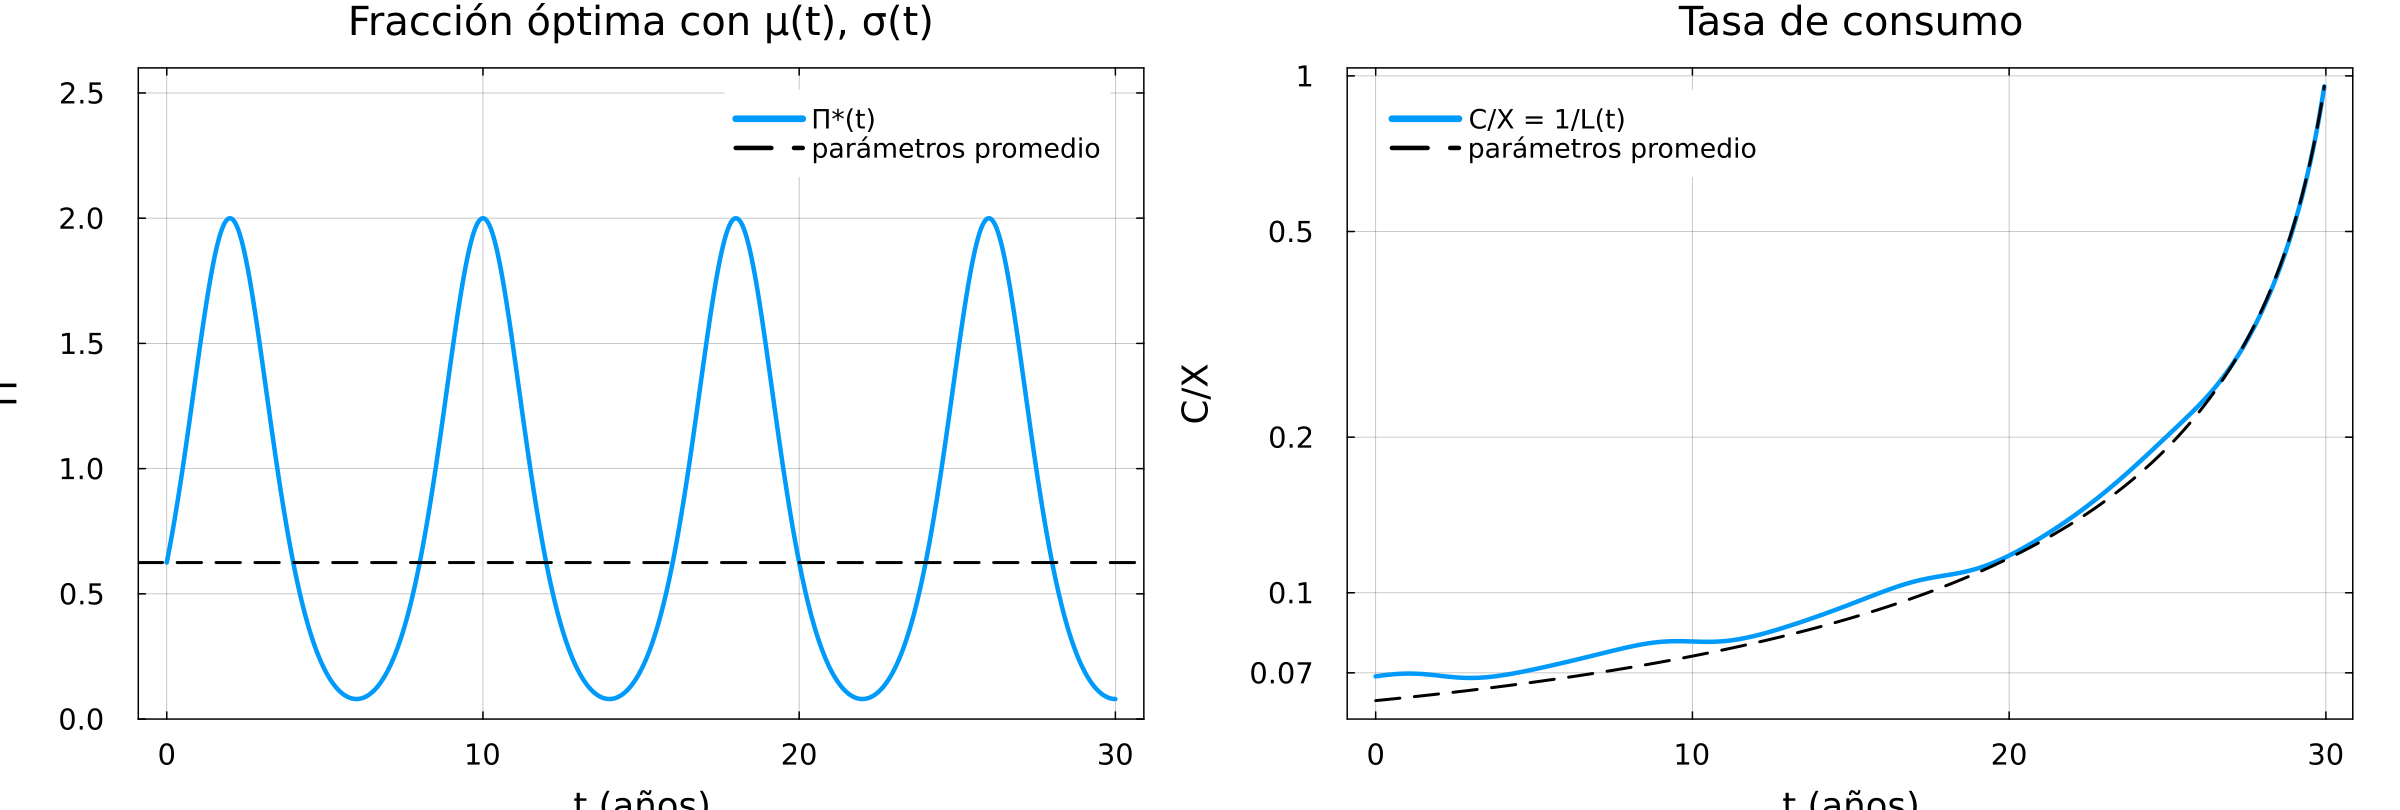

In [34]:
# Monte-Carlo con coeficientes congelados en cada paso diario; los dos inversionistas ven los mismos escenarios
function mc_tiempo(politica; N=20_000, h=1/252, semilla=2, P=par)
    rng = Xoshiro(semilla); K = round(Int, Tv/h)
    lX = fill(log(P.x0), N); Y = zeros(N)
    for k in 0:K-1
        t = k*h; Pi, e = politica(t)
        Y .+= (k == 0 ? h/2 : h)*exp(-P.gamma*t) .* U.(e .* exp.(lX))
        lX .+= (P.r + Pi*(mu_t(t) - P.r) - e - 0.5*sig_t(t)^2*Pi^2)*h .+ sig_t(t)*Pi*sqrt(h) .* randn(rng, N)
    end
    Pi, e = politica(Tv)
    return Y .+ (h/2)*exp(-P.gamma*Tv) .* U.(e .* exp.(lX)) .+ epsv*exp(-P.gamma*Tv) .* U.(exp.(lX))
end
Y_opt = mc_tiempo(t -> (Pi_t(t), 1/interp_t(ts_v, Ls_v, t)))
Y_cte = mc_tiempo(t -> (Pim, 1/L_const(Tv - t)))
d = Y_opt .- Y_cte
@printf("óptimo (Prop. 4.2):     Monte-Carlo = %.4f +- %.4f  vs  V(0,x0) = %.4f  ->  xCE = %.2f\n", mean(Y_opt), 1.96*std(Y_opt)/sqrt(length(d)), V0_v, xCE_v(mean(Y_opt)))
@printf("parámetros promedio:  Monte-Carlo = %.4f +- %.4f                       ->  xCE = %.2f\n", mean(Y_cte), 1.96*std(Y_cte)/sqrt(length(d)), xCE_v(mean(Y_cte)))
@printf("diferencia pareada:   %.4f +- %.4f\n", mean(d), 1.96*std(d)/sqrt(length(d)))

tt = range(0, Tv, length=600)
pv1 = plot(tt, Pi_t.(tt), label="Π*(t)", xlabel="t (años)", ylabel="Π", title="Fracción óptima con μ(t), σ(t)",
           legend=:topright, ylims=(0, 2.6))
hline!(pv1, [Pim], ls=:dash, color=:black, lw=2, label="parámetros promedio")
pv2 = plot(tt[1:end-1], 1 ./ interp_t.(Ref(ts_v), Ref(Ls_v), tt[1:end-1]), label="C/X = 1/L(t)", xlabel="t (años)",
           ylabel="C/X", title="Tasa de consumo", yscale=:log10, legend=:topleft,
           yticks=([0.07, 0.1, 0.2, 0.5, 1.0], ["0.07", "0.1", "0.2", "0.5", "1"]))
plot!(pv2, tt[1:end-1], 1 ./ L_const.(Tv .- tt[1:end-1]), ls=:dash, color=:black, lw=2, label="parámetros promedio")
savefig(plot(pv1, dpi=300), "figuras_poster/ciclo_fraccion.png")
savefig(plot(pv2, dpi=300), "figuras_poster/ciclo_consumo.png")
plot(pv1, pv2, layout=(1, 2), size=(1600, 540))

La fracción óptima sigue al ciclo: va de 0.08, cuando el retorno es bajo y la volatilidad alta, a 2.0 (apalancada) en la fase buena. La simulación coincide con la Proposición 4.2 dentro del intervalo de confianza (el capital equivalente del óptimo da 100.6 en vez de 100 solo por el error de Monte-Carlo, al que esta medida es muy sensible). Un inversionista que usa los parámetros promedio con la fórmula de Merton constante queda como si tuviera 83.5 de capital: conocer el ciclo vale alrededor de un 17%, y la diferencia pareada es muy significativa. Pero esto supone que el ciclo se **conoce**: la Sección 1 mostró que seguir un $\mu(t)$ variable con el filtro de Kalman es casi imposible con $\sigma=0.2$, así que en la práctica esta ganancia no está disponible.

### 4.3 Cambios acotados de la fracción invertida

Supongamos que la fracción no se puede cambiar de golpe: $\Pi_t$ pasa a ser un **estado**, con $\frac{d\Pi_t}{dt}=u_t$ y $|u_t|\le L_\Pi$ (a lo más $L_\Pi$ por año). En general esto da una HJB en dos variables $(x,\Pi)$, pero la homotecia la simplifica. Partimos de $\Pi_0=0$: un inversionista que hoy tiene todo en el banco y quiere llegar a $\Pi^*$.

**Proposición 4.3.** Con $\rho(p)=r+(\mu-r)p-\frac\eta2\sigma^2p^2$ (cóncava, con máximo en $\Pi^*$):
1. Por homotecia, $V(x,\Pi)=\frac{A(\Pi)}{1-\eta}x^{1-\eta}+K$, así que el control $u$ óptimo depende solo de $\Pi$ y el camino $\Pi(t)$ es **determinista**.
2. Para un camino determinista $\Pi(t)$, el valor es $\frac{1}{1-\eta}\big(L(0)^\eta x^{1-\eta}-\frac1\gamma\big)$, donde $L'=\nu(t)L-1$ con $\nu(t)=\frac{\gamma+(\eta-1)\rho(\Pi(t))}{\eta}$, y el consumo óptimo es $C=X/L(t)$.
3. El camino óptimo es ir **lo más rápido posible** hacia $\Pi^*$ y quedarse ahí: $\Pi(t)=\min(L_\Pi t,\Pi^*)$.

*Demostración.* (1) Escalar el capital no cambia la fracción, así que el argumento de la Prop. 2.1 vale con $\Pi$ fijo. (2) Es la Prop. 4.2 con $\theta(t)^2/(2\eta)$ reemplazado por $\rho(\Pi(t))-r$, porque con $\Pi$ dado solo se optimiza el consumo. (3) Todo camino admisible cumple $\Pi(t)\le L_\Pi t$, y $\rho$ es creciente en $(-\infty,\Pi^*]$, así que $\rho(\Pi(t))\le\rho(\min(L_\Pi t,\Pi^*))$ para todo $t$. La solución de la EDO lineal hacia atrás, $L(t)=e^{-\int_t^{t_1}\nu}L(t_1)+\int_t^{t_1}e^{-\int_t^s\nu}ds$, decrece cuando $\nu$ crece en todo instante, y para $\eta>1$ el valor crece cuando $L(0)$ decrece. Luego el camino más rápido es mejor que cualquier otro en cada instante. $\blacksquare$

Desde que se alcanza $\Pi^*$, en $t_1=\Pi^*/L_\Pi$, el problema es el de Merton y $L(t)=1/\nu$; antes resolvemos la EDO con RK4.

In [35]:
function valor_camino(LPi; P=par)
    t1 = Pim/LPi
    ts, Ls = L_rk4(t -> nu_p(min(LPi*t, Pim)), 0.0, t1, 1/nu; M=20_000)
    return (V=(Ls[1]^P.eta*P.x0^(1 - P.eta) - 1/P.gamma)/(1 - P.eta), t1=t1, ts=ts, Ls=Ls)
end

velocidades = [0.05, 0.1, 0.25, 0.5, 1.0, 5.0]
println("L_Pi (por año)   años hasta Pi*     V(x0)      xCE   C/X inicial")
for LPi in velocidades
    s = valor_camino(LPi)
    @printf("%10.2f %16.2f %12.4f %8.2f %10.4f\n", LPi, s.t1, s.V, xCE(s.V), 1/s.Ls[1])
end
V_banco = (nu_p(0.0)^(-par.eta)*par.x0^(1 - par.eta) - 1/par.gamma)/(1 - par.eta)
@printf("%10s %16s %12.4f %8.2f %10.4f\n", "0 (no cambia)", "nunca", V_banco, xCE(V_banco), nu_p(0.0))
@printf("%10s %16s %12.4f %8.2f %10.4f\n", "sin cota", "0", V(par.x0), 100.0, nu)

L_Pi (por año)   años hasta Pi*     V(x0)      xCE   C/X inicial
      0.05            12.50      15.3714    94.51     0.0465
      0.10             6.25      15.4912    97.02     0.0471
      0.25             2.50      15.5700    98.74     0.0475
      0.50             1.25      15.5975    99.36     0.0477
      1.00             0.62      15.6115    99.68     0.0477
      5.00             0.12      15.6228    99.94     0.0478
0 (no cambia)            nunca      13.7500    69.99     0.0400
  sin cota                0      15.6256   100.00     0.0478


L_Pi = 0.1: Monte-Carlo = 15.4837 +- 0.0222   vs   V(x0) = 15.4912


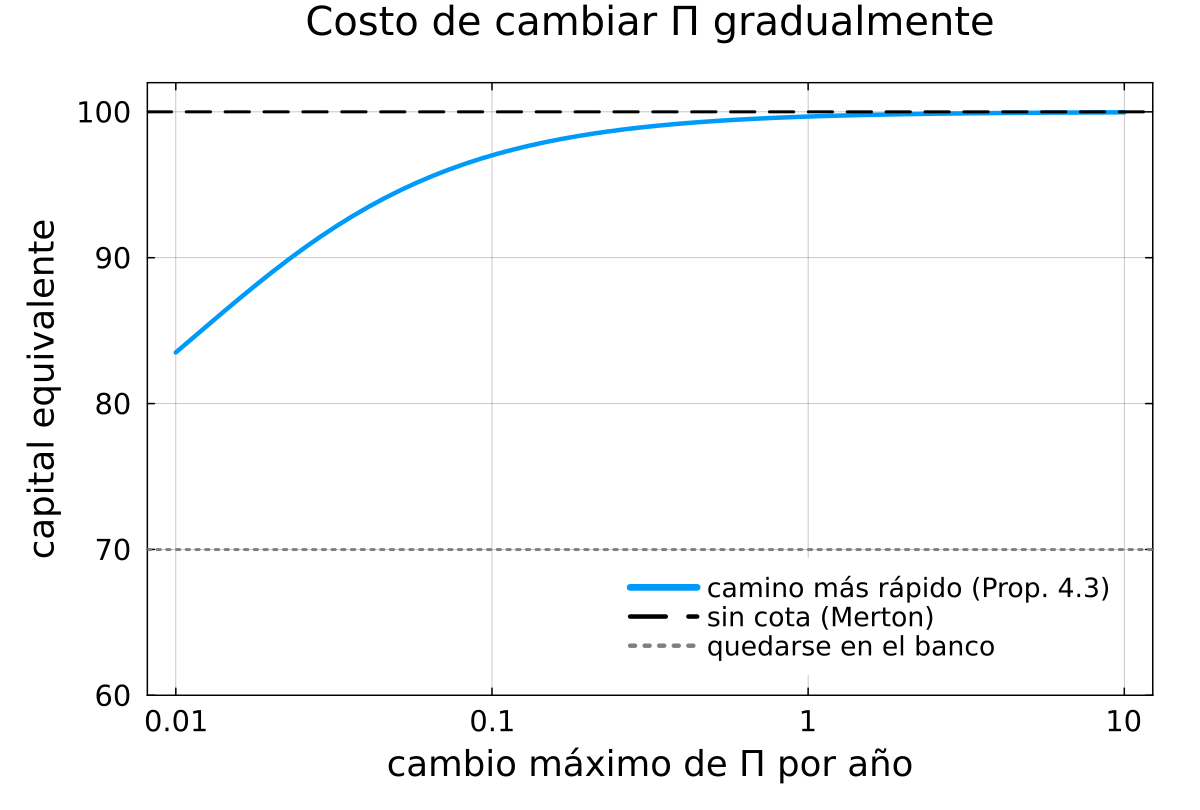

In [36]:
# validación por Monte-Carlo con L_Pi = 0.1: hasta T = 40 con el camino óptimo y después V(X_T) (ya es Merton)
s = valor_camino(0.1)
Random.seed!(3)
N, h, T3 = 20_000, 1/52, 40.0; K = round(Int, T3/h)
lX = fill(log(par.x0), N); Y = zeros(N)
for k in 0:K-1
    t = k*h; p = min(0.1*t, Pim); e = t < s.t1 ? 1/interp_t(s.ts, s.Ls, t) : nu
    Y .+= (k == 0 ? h/2 : h)*exp(-par.gamma*t) .* U.(e .* exp.(lX))
    lX .+= (par.r + p*(par.mu - par.r) - e - 0.5*par.sigma^2*p^2)*h .+ par.sigma*p*sqrt(h) .* randn(N)
end
Y .+= (h/2)*exp(-par.gamma*T3) .* U.(nu .* exp.(lX)) .+ exp(-par.gamma*T3) .* V.(exp.(lX))
@printf("L_Pi = 0.1: Monte-Carlo = %.4f +- %.4f   vs   V(x0) = %.4f\n", mean(Y), 1.96*std(Y)/sqrt(N), s.V)

vs = exp10.(range(-2, 1, length=60))
pc1 = plot(vs, [xCE(valor_camino(v).V) for v in vs], xscale=:log10, label="camino más rápido (Prop. 4.3)",
           xlabel="cambio máximo de Π por año", ylabel="capital equivalente", title="Costo de cambiar Π gradualmente",
           legend=:bottomright, ylims=(60, 102), xticks=([0.01, 0.1, 1, 10], ["0.01", "0.1", "1", "10"]))
hline!(pc1, [100], ls=:dash, color=:black, lw=2, label="sin cota (Merton)")
hline!(pc1, [xCE(V_banco)], ls=:dot, color=:gray, lw=2, label="quedarse en el banco")
savefig(plot(pc1, dpi=300), "figuras_poster/cambio_acotado.png")
pc1

No poder cambiar la fracción de golpe cuesta poco si la cota no es muy estricta: con $L_\Pi=1$ (llegar a $\Pi^*$ en 7 meses) se pierde 0.3% de capital equivalente, y con $L_\Pi=0.1$ (6 años) se pierde 3%. Solo con cambios muy lentos la pérdida se acerca a la de quedarse en el banco (30%). Mientras la fracción sube, el inversionista consume un poco menos que $\nu$, porque su rentabilidad todavía es baja. La simulación con $L_\Pi=0.1$ reproduce el valor de la Proposición 4.3.

### 4.4 Costos de transacción

Si cada compra o venta de acciones por un monto $|a|$ cuesta $\lambda|a|$ (costo proporcional), mantener $\Pi_t=\Pi^*$ exige transar todo el tiempo y es carísimo. La teoría [DN] dice que el óptimo es una **región de no transacción** alrededor de $\Pi^*$: no se transa mientras la fracción esté dentro, y se transa lo mínimo para volver al borde cuando sale. El problema es una desigualdad cuasivariacional sin solución explícita, así que comparamos estrategias de **banda** con Monte-Carlo:

* la cartera tiene $X^0$ en el banco y $X^1$ en la acción; se consume desde el banco con la tasa de Merton de horizonte finito, $C_t=X_t/L(T-t)$ (Sección 3, $T=20$, $\varepsilon=1$);
* cada semana, si la fracción $X^1/X$ sale de $[\Pi^*-\delta,\Pi^*+\delta]$, se compra o vende lo justo para volver al borde, pagando el costo. Para comprar $a>0$ y quedar en la fracción $p$ se resuelve $X^1+a=p\,(X-\lambda a)$, y análogamente para vender;
* $\delta=0$ es rebalancear a $\Pi^*$ todas las semanas.

El criterio es el de horizonte finito de la Sección 3, $\mathbb E\big[\int_0^Te^{-\gamma t}U(C_t)dt+\varepsilon e^{-\gamma T}U(X_T)\big]$ (con $X_T$ neto del costo de liquidar), y lo expresamos en capital equivalente respecto del óptimo sin costos. Todas las estrategias usan los mismos escenarios.

In [37]:
Tc, epsc = 20.0, 1.0
L_fin(s) = 1/nu + (epsc^(1/par.eta) - 1/nu)*exp(-nu*s)                     # Prop. 3.1
D_fin(s) = (1 - exp(-par.gamma*s))/par.gamma + epsc*exp(-par.gamma*s)
xCE_T(J) = (((1 - par.eta)*J + D_fin(Tc))/L_fin(Tc)^par.eta)^(1/(1 - par.eta))  # respecto del óptimo sin costos

# estrategia de banda [Pi* - delta, Pi* + delta] con costo proporcional lam; Z: escenarios semanales
function banda(delta, lam, Z; h=1/52, P=par)
    K, N = size(Z)
    X0 = fill((1 - Pim)*P.x0, N); X1 = fill(Pim*P.x0, N); Y = zeros(N)
    lo, hi = Pim - delta, Pim + delta
    for k in 1:K
        t = (k - 1)*h
        c = (X0 .+ X1) ./ L_fin(Tc - t)                                       # consumo desde el banco
        Y .+= (k == 1 ? h/2 : h)*exp(-P.gamma*t) .* U.(c)
        X0 .= X0 .* exp(P.r*h) .- c .* h
        X1 .*= exp.((P.mu - P.sigma^2/2)*h .+ P.sigma*sqrt(h) .* Z[k, :])
        for i in 1:N                                                          # rebalanceo semanal
            Xi = X0[i] + X1[i]; p = X1[i]/Xi
            if p > hi
                a = (hi*Xi - X1[i])/(1 - hi*lam)                              # vender (a < 0)
            elseif p < lo
                a = (lo*Xi - X1[i])/(1 + lo*lam)                              # comprar (a > 0)
            else
                continue
            end
            X1[i] += a; X0[i] -= a + lam*abs(a)
        end
    end
    XT = X0 .+ X1 .- lam .* X1                                                # liquidación final
    return Y .+ (h/2)*exp(-P.gamma*Tc) .* U.(XT ./ L_fin(0.0)) .+ epsc*exp(-P.gamma*Tc) .* U.(XT)
end

banda (generic function with 1 method)

In [38]:
Random.seed!(4)
Zc = randn(round(Int, 52Tc), 4_000)
deltas = [0.0, 0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.08, 0.10, 0.12, 0.15, 0.20]
lams = [0.001, 0.0025, 0.005, 0.01, 0.02, 0.04]
tabla = zeros(length(lams), length(deltas)); dstar = Float64[]
for (i, lam) in enumerate(lams)
    J = [mean(banda(d, lam, Zc)) for d in deltas]
    tabla[i, :] = xCE_T.(J)
    j = clamp(argmax(J), 2, length(deltas) - 1)                               # parábola por los 3 puntos del máximo
    (x1, x2, x3), (y1, y2, y3) = deltas[j-1:j+1], J[j-1:j+1]
    den = (x1 - x2)*(x1 - x3)*(x2 - x3)
    A = (x3*(y2 - y1) + x2*(y1 - y3) + x1*(y3 - y2))/den
    B = (x3^2*(y1 - y2) + x2^2*(y3 - y1) + x1^2*(y2 - y3))/den
    push!(dstar, -B/(2A))
end
@printf("sin costos, rebalanceo semanal (delta = 0): xCE = %.2f\n\n", xCE_T(mean(banda(0.0, 0.0, Zc))))
println("capital equivalente según el ancho de la banda delta:")
println("    lam  ", join([@sprintf("%7.2f", d) for d in deltas]), "   delta*")
for (i, lam) in enumerate(lams)
    println(@sprintf("%7.4f  ", lam), join([@sprintf("%7.2f", v) for v in tabla[i, :]]), @sprintf("   %.3f", dstar[i]))
end
lx, ly = log.(lams), log.(dstar)
@printf("\npendiente de log(delta*) contra log(lam): %.2f  (ley asintótica de [DN] con rebalanceo continuo: 1/3)\n",
        sum((lx .- mean(lx)) .* (ly .- mean(ly)))/sum((lx .- mean(lx)).^2))

sin costos, rebalanceo semanal (delta = 0): xCE = 99.79

capital equivalente según el ancho de la banda delta:
    lam     0.00   0.01   0.02   0.03   0.04   0.05   0.06   0.08   0.10   0.12   0.15   0.20   delta*
 0.0010    99.55  99.70  99.70  99.69  99.67  99.64  99.62  99.56  99.47  99.36  99.17  98.77   0.017
 0.0025    99.18  99.56  99.60  99.59  99.57  99.55  99.53  99.46  99.38  99.27  99.08  98.68   0.024
 0.0050    98.57  99.34  99.42  99.43  99.41  99.39  99.37  99.31  99.22  99.11  98.93  98.53   0.029
 0.0100    97.36  98.88  99.06  99.10  99.10  99.08  99.06  99.00  98.91  98.80  98.62  98.22   0.034
 0.0200    94.96  97.96  98.35  98.44  98.45  98.44  98.42  98.37  98.29  98.18  97.99  97.59   0.041
 0.0400    90.21  96.11  96.89  97.08  97.13  97.14  97.13  97.08  97.00  96.89  96.71  96.30   0.048

pendiente de log(delta*) contra log(lam): 0.27  (ley asintótica de [DN] con rebalanceo continuo: 1/3)


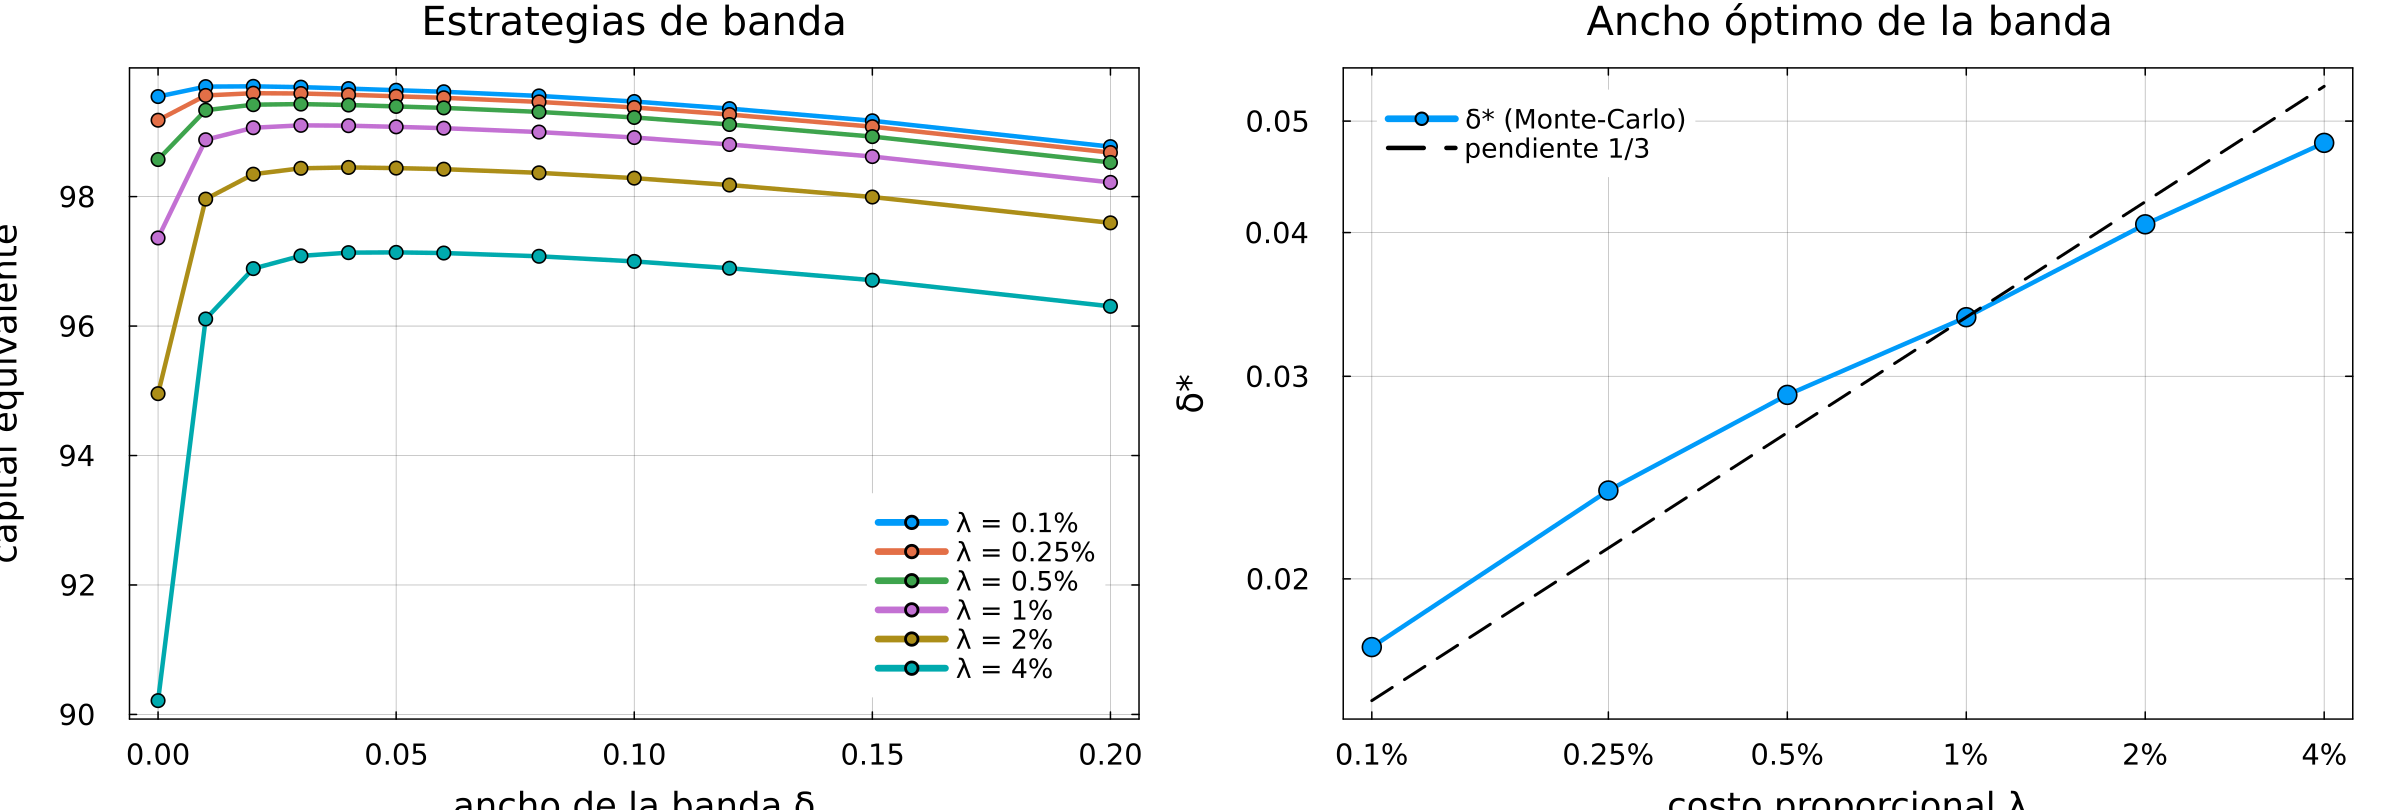

In [39]:
pt1 = plot(xlabel="ancho de la banda δ", ylabel="capital equivalente", title="Estrategias de banda", legend=:bottomright)
lam_txt = ["0.1%", "0.25%", "0.5%", "1%", "2%", "4%"]
for (i, lam) in enumerate(lams)
    plot!(pt1, deltas, tabla[i, :], marker=:circle, ms=5, label="λ = $(lam_txt[i])")
end
pt2 = plot(lams, dstar, xscale=:log10, yscale=:log10, marker=:circle, label="δ* (Monte-Carlo)",
           xlabel="costo proporcional λ", ylabel="δ*", title="Ancho óptimo de la banda", legend=:topleft,
           xticks=(lams, lam_txt), yticks=([0.02, 0.03, 0.04, 0.05], ["0.02", "0.03", "0.04", "0.05"]))
plot!(pt2, lams, dstar[4] .* (lams ./ lams[4]).^(1/3), ls=:dash, color=:black, lw=2, label="pendiente 1/3")
savefig(plot(pt1, dpi=300), "figuras_poster/costos_bandas.png")
savefig(plot(pt2, dpi=300), "figuras_poster/costos_ancho_optimo.png")
plot(pt1, pt2, layout=(1, 2), size=(1600, 540))

Los costos de transacción cambian bastante la estrategia:

* **Rebalancear a $\Pi^*$ todas las semanas es caro:** con un costo de 1% equivale a tener 97.4 de capital, y con 4%, 90.2.
* **Una banda angosta recupera casi todo:** con $\lambda=1\%$ y una banda de $\pm0.03$ a $\pm0.04$ se llega a 99.1, cerca del óptimo sin costos con rebalanceo semanal (99.8). Con una banda más ancha se vuelve a perder, porque la fracción se aleja demasiado de $\Pi^*$.
* El ancho óptimo crece con el costo: de 0.017 con $\lambda=0.1\%$ a 0.048 con $\lambda=4\%$. La pendiente en escala logarítmica (0.27) es cercana al exponente 1/3 de la teoría [DN], pero la estimación es ruidosa porque las curvas son muy planas cerca del máximo. Además, nuestro modelo rebalancea semanalmente y tiene horizonte finito, mientras que la ley 1/3 es para rebalanceo continuo y horizonte infinito.

In [40]:
# figura del reporte: tres paneles en una fila con letras más chicas
fig = plot(pv1, pc1, pt1, layout=(1, 3), size=(1200, 340), titlefontsize=10, guidefontsize=9, tickfontsize=8,
           legendfontsize=6, bottom_margin=6Plots.mm, left_margin=5Plots.mm)
mkpath("figuras_final"); savefig(fig, "figuras_final/extensiones.pdf");

### 4.5 Conclusiones y pendientes

**Conclusiones.**
1. **Varios activos:** la solución de Merton se generaliza con $\Pi^*=\frac1\eta\Sigma^{-1}(\mu-r\mathbf 1)$. Todos los inversionistas compran el mismo fondo de acciones, y en nuestro ejemplo diversificar entre tres acciones vale un 17% de capital equivalente.
2. **$\mu(t)$ y $\sigma(t)$ conocidos:** el control óptimo aplica la fórmula de Merton instante a instante, con un consumo que sale de una EDO lineal. Conocer el ciclo vale mucho, pero en la práctica no se puede estimar (Sección 1).
3. **Cambios acotados de $\Pi$:** por homotecia el problema se reduce a una EDO, y el camino óptimo es ir lo más rápido posible hacia $\Pi^*$. La pérdida es pequeña salvo con cotas muy estrictas.
4. **Costos de transacción:** rebalancear todo el tiempo es muy caro. Una banda de no transacción de $\pm0.02$ a $\pm0.05$ recupera casi todo, y su ancho crece con el costo, aproximadamente como $\lambda^{1/3}$.

**Pendientes.**
* Resolver en forma exacta el problema con costos de transacción (la desigualdad cuasivariacional de [DN]), que además optimiza el consumo y permite una banda no simétrica, en vez de comparar estrategias de banda.
* Estudiar el caso en que $\mu(t)$ es desconocido y se estima mientras se invierte (información parcial), que junta este avance con el 3.
* Volatilidad estocástica y saltos en el precio, que el enunciado deja abiertos ("entre otras").